# Итоговый проект: гибридная система рекомендаций книг с нейросетевой моделью (Goodbooks-10k)

**Цель.** На основе домашней работы `HW_1_FINAL.ipynb` (Popularity, Content-Based, Item-Based CF, SVD) построить полноценную гибридную систему рекомендаций. Система должна генерировать общий пул кандидатов, нормализовать и смешивать score нескольких моделей с весами, подобранными на validation, учитывать активность пользователя, балансировать персонализацию с популярностью и релевантность с разнообразием. В неё также встраивается нейросетевая Two-Tower модель на PyTorch. Модели сравниваются в едином честном протоколе.

**Структура ноутбука**

1. Что взято из HW_1_FINAL и что изменено
2. Данные: загрузка, проверки, очистка, разбиение train / validation / test
3. Признаки пользователей, книг и взаимодействий
4. Модели HW_1_FINAL в единой архитектуре и подбор их гиперпараметров на validation
5. Нейросетевая модель Two-Tower
6. Гибридная система: кандидаты → нормализация → смешивание → балансировка (подбор на validation)
7. Финальная оценка на test: все модели и гибриды, сегменты, значимость, протокол HW1, cold start
8. Рекомендации через сервисный интерфейс
9. Сквозной пайплайн и артефакты
10. Выводы, сильные и слабые стороны, рекомендации по выбору моделей, ограничения

Код вынесен в пакет `recsys/` (см. `README.md`), ноутбук вызывает его по шагам и документирует решения. Полный прогон занимает ≈ 20–30 минут на CPU.

## 1. Что взято из HW_1_FINAL и что изменено

Исходный ноутбук `HW_1_FINAL.ipynb` не изменялся. Его решения перенесены в модули и доработаны:

| Элемент HW_1_FINAL | В итоговом проекте |
|---|---|
| Per-user random holdout 80/20, `RANDOM_STATE = 42`, усреднение дублей | **Сохранён без изменений** (test идентичен HW1); из train дополнительно выделен **validation** тем же способом (seed 43) |
| Релевантность `rating >= 4`, метрики Precision/Recall/nDCG@K | Сохранены (те же определения; векторизованная версия покрыта тестами против эталонных) |
| Popularity: weighted rating по train, `m` = медиана поддержки | Сохранена; вариант score выбирается на validation |
| Content-Based: TF-IDF `title + top-25 tags`, профиль = среднее понравившихся книг | Сохранён; профиль `enhanced` (без служебных тегов, с авторами) выбирается на validation |
| Item-Based CF: cosine по sparse-матрице оценок, взвешенное среднее оценок соседей | Хранятся только top-k соседей (батчевый расчёт, без плотной 10000×10000); агрегатор и k подбираются на validation |
| SVD (surprise, 100 факторов) | Сохранён (Funk SVD, подбор по RMSE на validation) + адаптация для top-N: PureSVD |
| Гибрид: жёсткое переключение Popularity / CB / SVD по длине истории | Сохранён как baseline **Hybrid-Switch (HW1)**; построен полноценный взвешенный гибрид |
| Fair evaluation: relevant + 100 негативов, 1000 пользователей | Воспроизведён на test как дополнительный протокол; основной — full-catalog candidate generation + pooled hybrid ranking (раздел 7) |

In [1]:
%matplotlib inline
import os, platform, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from IPython.display import display, Markdown

from recsys.config import Config, HW1_REFERENCE
from recsys import data as D, features as F, models as Mo, hybrid as H, evaluation as E, plots as P
from recsys import pipeline as PL
from recsys.two_tower import TwoTowerScorer
from recsys.utils import set_seed, timer, save_json

cfg = Config()
if os.environ.get("RECSYS_FAST") == "1":   # быстрый режим проверки: меньше пользователей и эпох
    cfg = PL.fast_config(cfg)
cfg.ensure_dirs()
set_seed(cfg.random_state)
torch.set_num_threads(os.cpu_count() or 1)
pd.set_option("display.float_format", "{:.4f}".format)
pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 220)
pd.set_option("display.max_colwidth", 80)
FIG, RES = cfg.figures_dir, cfg.results_dir

print("Данные:", cfg.data_path, "| найдены:", cfg.data_path.exists())
print("Python", platform.python_version(), "| numpy", np.__version__, "| pandas", pd.__version__,
      "| torch", torch.__version__, "| CPU threads", torch.get_num_threads())
T0 = time.perf_counter()

Данные: C:\Users\Sergey\Documents\Личное\Учеба\3 Семестр\Рекомендательные системы\ИТОГОВЫЙ ПРОЕКТ\archive.zip | найдены: True
Python 3.13.7 | numpy 2.3.3 | pandas 2.3.3 | torch 2.11.0+cpu | CPU threads 8


## 2. Данные

### 2.1 Загрузка, проверки и очистка

CSV читаются **напрямую из `archive.zip`** в корне курса, без распаковки и копирования. Путь можно переопределить переменной окружения `GOODBOOKS_DATA`, указав zip или папку с CSV.

`validate_raw` проверяет схемы, диапазон `rating ∈ [1, 5]`, отсутствие пропусков в ключах и ссылочную целостность. Проверяется, что `ratings.book_id → books.id`, а `book_tags.goodreads_book_id → books.book_id`; эту путаницу ID выявила EDA в HW1. Повторные пары `(user_id, book_id)` усредняются, как в HW1.

In [2]:
with timer("Загрузка, проверки, очистка, разбиение, контентный каталог"):
    prep = PL.prepare_data(cfg)
s = prep.splits
display(prep.quality_report)
print(f"Уникальных взаимодействий после усреднения дублей: {len(prep.interactions):,}")
print(f"Пользователей: {prep.index.n_users:,}, книг: {prep.index.n_items:,}")

[Загрузка, проверки, очистка, разбиение, контентный каталог] 7.3 c


,dataset,rows,columns,missing_cells,full_duplicates,duplicate_user_book_pairs
0,ratings,981756,3,0,1644,2278.0000
1,books,10000,23,2975,0,NaN
2,tags,34252,2,0,0,NaN
3,book_tags,999912,3,0,6,NaN


Уникальных взаимодействий после усреднения дублей: 979,478
Пользователей: 53,424, книг: 10,000


### 2.2 Разбиение train / validation / test

В `ratings.csv` нет timestamp, поэтому temporal split невозможен. Используется воспроизводимый per-user random holdout из HW1: для пользователя с $n \ge 2$ оценками в holdout уходит $\min(\max(1, \lfloor 0.2n \rfloor), n-1)$ взаимодействий, хотя бы одно остаётся в обучении.

1. **test** = holdout от всех взаимодействий (seed 42). Он **идентичен** `test_df` из HW1, а `train_full = train + validation` идентичен `train_df` из HW1.
2. **validation** = holdout от `train_full` (seed 43). На нём подбираются гиперпараметры моделей, веса гибрида, λ MMR, стратегия cold start, выбирается Two-Tower и выполняется early stopping.
3. После подбора все модели **переобучаются на `train_full`** с зафиксированными настройками, и test используется **один раз** — для финальной оценки.

Отсутствие пересечений и корректность объединений проверяются assert-ами в `D.check_no_leakage`.

In [3]:
display(D.split_summary(s))
D.check_no_leakage(s, n_interactions=len(prep.interactions))
assert len(s.train_full) == 788_503 and len(s.test) == 190_975, "test должен совпадать с HW_1_FINAL"
assert s.train_full.index.equals(s.train_full.index.unique())
print("OK: train_full и test совпадают по составу с train_df / test_df HW_1_FINAL;")
print("OK: пары (user_id, book_id) не пересекаются между train, validation и test;")
print("OK: у каждого validation/test-пользователя есть история в соответствующей обучающей части.")

,part,interactions,users,books,share_relevant(>=4),median_per_user
0,train,639011,53424,10000,0.6624,6.0000
1,val,149492,45071,9999,0.6621,1.0000
2,train_full,788503,53424,10000,0.6623,7.0000
3,test,190975,53382,10000,0.6616,1.0000


OK: train_full и test совпадают по составу с train_df / test_df HW_1_FINAL;
OK: пары (user_id, book_id) не пересекаются между train, validation и test;
OK: у каждого validation/test-пользователя есть история в соответствующей обучающей части.


### 2.3 Важное свойство выборки: cap ≈ 100 оценок на книгу

EDA в HW1 показала, что в `ratings.csv` у каждой книги не больше ~100 оценок. Отсюда следует неочевидный эффект: при per-user split **чем больше оценок книги попало в обучение, тем меньше их осталось в holdout**, потому что сумма почти постоянна. Проверим это: от этого зависит, может ли «популярность внутри обучающей выборки» предсказывать test.

corr(#оценок книги в train_full, #оценок в test) = -0.563
corr(#оценок книги в train,      #оценок в val)  = -0.233


,среднее #оценок в test,книг
"(0, 60]",20.1528,288
"(60, 70]",23.0654,474
"(70, 74]",24.1393,804
"(74, 77]",22.6306,1462
"(77, 80]",20.2763,2385
"(80, 83]",17.6526,2516
"(83, 86]",14.8701,1493
"(86, 100]",11.7128,578


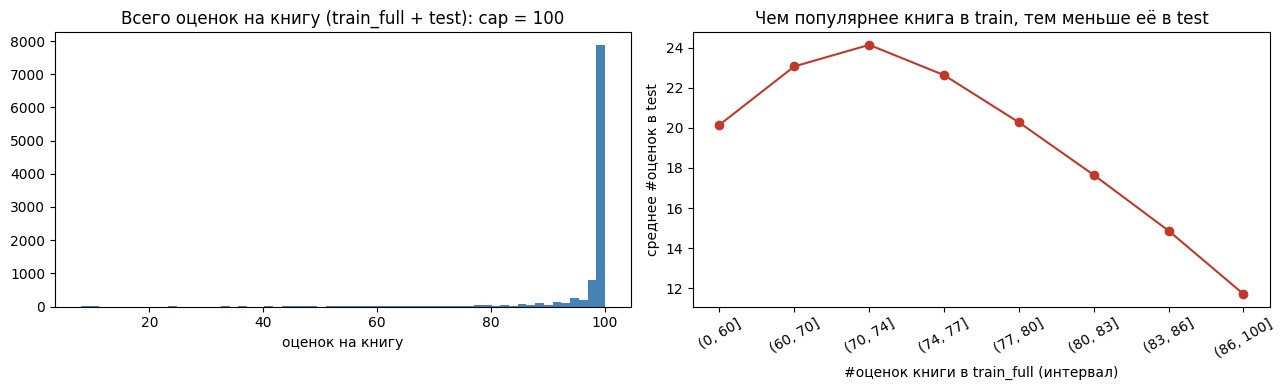

In [4]:
def cap_effect(train_part, holdout_part, name):
    c_tr = train_part.groupby("book_id").size()
    c_ho = holdout_part.groupby("book_id").size().reindex(c_tr.index, fill_value=0)
    corr = np.corrcoef(c_tr, c_ho)[0, 1]
    bins = pd.cut(c_tr, [0, 60, 70, 74, 77, 80, 83, 86, 100])
    return corr, pd.DataFrame({"train": c_tr, "holdout": c_ho}).groupby(bins, observed=True)["holdout"].agg(["mean", "size"]), c_tr + c_ho

corr_t, bins_t, total_t = cap_effect(s.train_full, s.test, "test")
corr_v, bins_v, _ = cap_effect(s.train, s.val, "val")
print(f"corr(#оценок книги в train_full, #оценок в test) = {corr_t:+.3f}")
print(f"corr(#оценок книги в train,      #оценок в val)  = {corr_v:+.3f}")
display(bins_t.rename(columns={"mean": "среднее #оценок в test", "size": "книг"}))

fig, ax = plt.subplots(1, 2, figsize=(13, 4))
ax[0].hist(total_t, bins=60, color="steelblue")
ax[0].set_title("Всего оценок на книгу (train_full + test): cap = 100")
ax[0].set_xlabel("оценок на книгу")
ax[1].plot(bins_t.index.astype(str), bins_t["mean"], "o-", color="#c0392b")
ax[1].set_title("Чем популярнее книга в train, тем меньше её в test")
ax[1].set_xlabel("#оценок книги в train_full (интервал)")
ax[1].set_ylabel("среднее #оценок в test")
plt.xticks(rotation=30)
fig.tight_layout()
fig.savefig(FIG / "cap_effect.png", dpi=120)
plt.show()

**Вывод.** Корреляция отрицательная: это артефакт cap, а не свойство читателей. Неперсонализированная популярность, посчитанная по train, в этой выборке почти не может предсказать test. Это не ошибка реализации, а ограничение данных, и оно объясняет низкие результаты Popularity при ранжировании всего каталога (раздел 7). Внешний `books.ratings_count` (глобальная популярность Goodreads) мог бы обойти артефакт. Но это агрегат, включающий и test-оценки, поэтому в соответствии с HW1 он в модели не включается.

## 3. Признаки

Признаки делятся на две группы.

* **Не зависящие от рейтингов** (контентный каталог `F.build_catalog`): TF-IDF профили книг, тематики, автор, год. Они строятся по метаданным всего каталога: в них нет информации о test.
* **Зависящие от рейтингов** (`F.build_item_features`, `F.build_user_features`): вычисляются **только по переданной обучающей части**. Функция `Mo.fit_context(train, ...)` строит их и проверяет assert-ами, что суммарное число оценок в признаках равно `len(train)`, а глобальное среднее совпадает со средним train. На этапе validation это `train`, на этапе test — `train_full`. Test в признаки не попадает никогда.

Тематические категории получены NMF-разложением матрицы тегов (теги-токены целиком, без служебных `to-read`, `favorites`, `owned`, …): 20 тем с интерпретируемыми названиями.

In [5]:
ctx_v = Mo.fit_context(s.train, prep.index, prep.catalog, cfg)   # признаки этапа validation: только train
rel_val = E.relevance_matrix(s.val, prep.index, cfg.relevance_threshold)
display(F.feature_descriptions())

,group,feature,definition,purpose
0,user,user_n_ratings / user_log_n,число оценок в train (активность),сегментация new/short/medium/active и веса гибрида; признак башни пользователя
1,user,"user_mean, user_std",средняя и разброс оценок пользователя в train,строгость и «шкала» пользователя; признаки башни пользователя
2,user,user_share_pos,доля оценок >= 4,склонность ставить высокие оценки
3,user,user_bias_shrunk,(sum r - n*mu)/(n+5),"смещение пользователя, сглаженное к 0 при короткой истории"
4,user,user_mainstreamness,средний популярностный перцентиль прочитанных книг,насколько пользователю подходит популярное: баланс персонализации и популярн...
5,user,user_taste_diversity,1 - ||среднее контентных эмбеддингов истории||,широта вкуса (0 = одна тематика)
6,user,segment,new / short (1-5) / medium (6-20) / active (>20),отдельные веса гибрида по сегментам
7,user,topic_profile,среднее тематик NMF понравившихся книг,тематический профиль; вход башни пользователя
8,item,item_n_ratings / item_log_n,число оценок книги в train,популярность внутри обучающей выборки
9,item,"item_mean, item_std",средняя и разброс оценок книги в train,качество и спорность книги


In [6]:
uf = ctx_v.user_feats
num_cols = ["user_n_ratings", "user_mean", "user_std", "user_share_pos", "user_bias_shrunk",
            "user_mainstreamness", "user_taste_diversity"]
seg_stats = uf.groupby("segment")[num_cols].mean().reindex(["short", "medium", "active"])
seg_stats.insert(0, "users", uf["segment"].value_counts())
print("Признаки пользователей по сегментам активности (train этапа validation):")
display(seg_stats)

print("Признаки книг (train этапа validation):")
display(ctx_v.item_feats.describe().T[["mean", "std", "min", "50%", "max"]])

cat = prep.catalog
topics = pd.DataFrame({"тема (top-4 тега NMF)": cat.topic_names,
                       "книг (доминирующая тема)": np.bincount(cat.books["dominant_topic"], minlength=cfg.n_topics)})
print("Тематические категории книг:")
display(topics.sort_values("книг (доминирующая тема)", ascending=False))

Признаки пользователей по сегментам активности (train этапа validation):


,users,user_n_ratings,user_mean,user_std,user_share_pos,user_bias_shrunk,user_mainstreamness,user_taste_diversity
segment,,,,,,,,
short,25571,2.0284,3.8949,0.2536,0.6804,0.0090,0.3153,0.1024
medium,18840,11.0853,3.8640,0.7539,0.6655,0.0040,0.5111,0.3564
active,9013,41.9723,3.8550,0.7950,0.6621,-0.0020,0.5582,0.4313


Признаки книг (train этапа validation):


,mean,std,min,50%,max
item_n_ratings,63.9011,6.8476,6.0000,65.0000,83.0000
item_log_n,4.1663,0.1215,1.9459,4.1897,4.4308
item_mean,3.8573,0.3108,1.9701,3.8750,4.8125
item_std,0.9252,0.1293,0.4697,0.9177,1.7430
item_share_pos,0.6626,0.1322,0.0448,0.6724,0.9841
item_weighted_rating,3.8569,0.1533,2.8992,3.8654,4.3405
item_pop_pct,0.5000,0.2883,0.0001,0.5268,1.0000
item_year_norm,0.0000,0.9970,-18.3204,0.2781,0.5517


Тематические категории книг:


,тема (top-4 тега NMF),книг (доминирующая тема)
3,"mystery-thriller, crime, mystery, thriller",1091
1,"children-s, children, childrens, kids",857
12,"historical, historical-fiction, history, war",802
6,"paranormal, urban-fantasy, supernatural, paranormal-romance",776
10,"contemporary-romance, new-adult, romance, contemporary",572
11,"self-help, psychology, self-improvement, non-fiction",561
4,"biography, memoir, memoirs, biography-memoir",558
2,"literature, novels, 1001-books, 1001",550
14,"audiobooks, read-in-2016, audio, read-in-2015",513
8,"ya, young-adult, teen, realistic-fiction",500


Сегменты получены из `user_n_ratings`. С ростом активности растёт широта вкуса (`user_taste_diversity`) и снижается `user_mainstreamness`: опытные читатели чаще выбирают менее популярные книги. Поэтому веса гибрида настраиваются отдельно для каждого сегмента (раздел 6).

Признаки взаимодействий (`cb`, `icf`, `author`, `topic`) считаются для пары «пользователь–книга» по train-истории пользователя. Их полезность проверяется ниже: отдельно по AUC и в составе гибрида через ablation.

## 4. Модели HW_1_FINAL в единой архитектуре

Все модели реализуют один интерфейс: `fit(ctx)` получает только обучающую часть, `score(users)` возвращает score **всего каталога** для батча пользователей. Вычисления идут на sparse-матрицах и пакетами; плотные матрицы `users × books` и `books × books` целиком не создаются.

| Сигнал | Модель | Что считает |
|---|---|---|
| `pop` | Popularity | weighted rating книги по train (или другой вариант, выбранный на validation) |
| `cb` | Content-Based | косинус TF-IDF-профиля понравившихся книг и книги |
| `icf` | Item-Based CF | агрегат сходства книги с историей по top-k соседям (cosine по оценкам) |
| `svd` | SVD (Funk, surprise) | предсказанный рейтинг $\mu + b_u + b_i + p_u^\top q_i$ |
| `psvd` | PureSVD | $b_u V V^\top$: SVD бинарной матрицы, адаптация SVD для top-N |
| `author`, `topic` | признаки взаимодействий | доля истории у автора книги; соответствие тематическому профилю |
| `tt` | Two-Tower | косинус эмбеддингов пользователя и книги (раздел 5) |

### 4.1 Подбор гиперпараметров на validation

Метрика — nDCG@10 при ранжировании всего каталога без прочитанного, на 3000 validation-пользователей. Funk SVD — модель предсказания оценки, поэтому для неё критерий — RMSE на validation (как в HW1).

In [7]:
tune_users = E.sample_eval_users(rel_val, ctx_v, cfg.n_tune_users, cfg.random_state + 1)
with timer("Подбор гиперпараметров отдельных моделей"):
    params, comp_table, _ = PL.tune_components(ctx_v, s.val, rel_val, tune_users, cfg, verbose=False)
comp_table.to_csv(RES / "val_component_tuning.csv", index=False)
display(comp_table)
print("Выбрано на validation:", params)

[Подбор гиперпараметров отдельных моделей] 62.3 c


,model,variant,Precision@10,Recall@10,nDCG@10,val_RMSE
0,Popularity,weighted_rating,0.0003,0.0017,0.0009,NaN
1,Popularity,n_ratings,0.0001,0.0003,0.0003,NaN
2,Popularity,share_pos,0.0002,0.0009,0.0005,NaN
3,Content-Based,base,0.0352,0.1549,0.1095,NaN
4,Content-Based,enhanced,0.0371,0.1623,0.1152,NaN
5,Item-Based CF,"mode=avg, k=20",0.0079,0.0471,0.0261,NaN
6,Item-Based CF,"mode=avg, k=50",0.0038,0.0238,0.0130,NaN
7,Item-Based CF,"mode=avg, k=100",0.0026,0.0180,0.0089,NaN
8,Item-Based CF,"mode=avg, k=200",0.0017,0.0097,0.0050,NaN
9,Item-Based CF,"mode=sum_centered, k=20",0.0376,0.1380,0.1089,NaN


Выбрано на validation: ComponentParams(pop_kind='weighted_rating', cb_profile='enhanced', icf_mode='sum_liked', icf_k=20, svd_params={'n_factors': 50, 'n_epochs': 30, 'lr_all': 0.005, 'reg_all': 0.05}, psvd_k=384, tt_epochs=None)


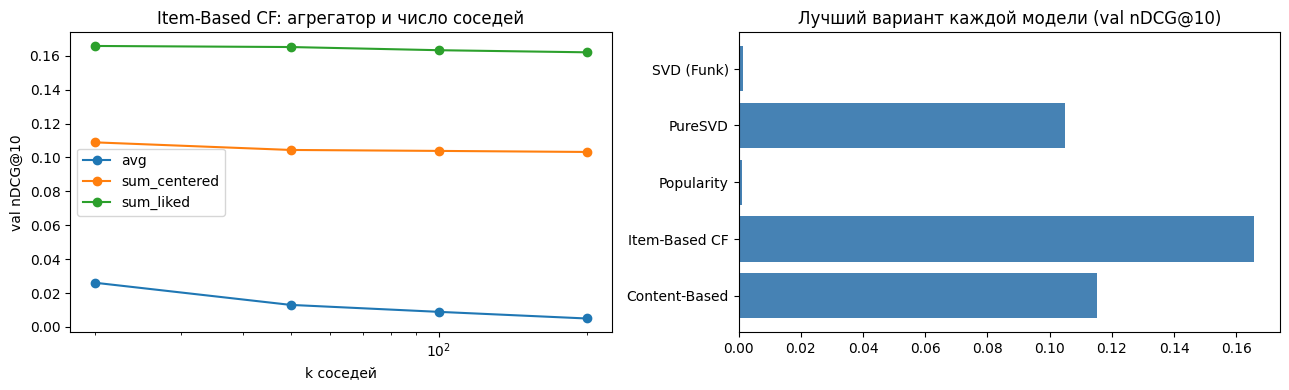

In [8]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
icf_t = comp_table[comp_table["model"] == "Item-Based CF"].copy()
icf_t["mode"] = icf_t["variant"].str.extract(r"mode=(\w+)")
icf_t["k"] = icf_t["variant"].str.extract(r"k=(\d+)").astype(int)
for mode, g in icf_t.groupby("mode"):
    ax[0].plot(g["k"], g["nDCG@10"], "o-", label=mode)
ax[0].set_xscale("log"); ax[0].set_xlabel("k соседей"); ax[0].set_ylabel("val nDCG@10")
ax[0].set_title("Item-Based CF: агрегатор и число соседей"); ax[0].legend()
best_rows = comp_table.loc[comp_table.groupby("model")["nDCG@10"].idxmax()].set_index("model")["nDCG@10"]
ax[1].barh(best_rows.index, best_rows.values, color="steelblue")
ax[1].set_title("Лучший вариант каждой модели (val nDCG@10)")
fig.tight_layout(); fig.savefig(FIG / "val_component_tuning.png", dpi=120); plt.show()

**Интерпретация подбора.**

* **Item-Based CF.** Агрегатор HW1 (`avg`, взвешенное среднее оценок соседей) плохо ранжирует. Он предсказывает величину оценки и выносит наверх книги с единственным соседом, оценённым на 5. Сумма сходств с понравившимися книгами (`sum_liked`) оценивает, *насколько книга близка к тому, что пользователь читает и любит*, и даёт кратно лучший nDCG.
* **Content-Based.** Профиль `enhanced` (авторы, без служебных тегов) лучше базового профиля HW1. Это прямое подтверждение пользы очистки тематических признаков.
* **Popularity и Funk SVD** в full-catalog ранжировании почти нулевые. Обе модели оценивают «насколько высоко оценят» (weighted rating, $\hat r_{ui}$), а не «возьмёт ли пользователь книгу», а популярность к тому же подавлена cap-артефактом (раздел 2.3). Чем больше факторов у PureSVD (SVD по факту взаимодействия), тем лучше он ранжирует. Это показывает, что проблема в целевой переменной, а не в матричной факторизации как таковой.

In [9]:
with timer("Обучение классических моделей на train"):
    sc_v = PL.fit_classic_scorers(ctx_v, params, cfg)

# Информативность сигналов: AUC = P(score релевантной val-книги > score случайной непрочитанной книги)
rng = np.random.default_rng(cfg.random_state)
auc_users = tune_users[:2000]
seen = ctx_v.R[auc_users]
relu = rel_val[auc_users]
ru, ri = relu.nonzero()
rand_items = rng.integers(0, ctx_v.n_items, size=len(ru))
ok = np.asarray(seen[ru, rand_items]).ravel() == 0
auc = {}
for name, scorer in sc_v.items():
    Z = H.zscore_unseen(scorer.score(auc_users), seen)
    a, b = Z[ru[ok], ri[ok]], Z[ru[ok], rand_items[ok]]
    auc[Mo.MODEL_TITLES[name]] = float(np.mean(a > b) + 0.5 * np.mean(a == b))
auc_df = pd.Series(auc, name="AUC (val)").sort_values(ascending=False).to_frame()
display(auc_df)

[Popularity] 0.0 c
[Content-Based] 0.0 c


[Item-Based CF (top-k соседей, батчами)] 1.1 c


[SVD (Funk, surprise)] 7.7 c


[PureSVD] 10.9 c
[Обучение классических моделей на train] 19.8 c


,AUC (val)
"SVD (PureSVD, top-N)",0.8922
Content-Based,0.8901
Topic affinity,0.8495
Item-Based CF,0.7850
Author affinity,0.6827
"SVD (Funk, HW1)",0.5445
Popularity,0.5392


AUC показывает, насколько каждый сигнал отличает понравившуюся validation-книгу от случайной непрочитанной (0.5 — случайное угадывание). Сигналы различаются и по силе, и по природе: коллаборативные (`icf`, `psvd`), контентные (`cb`, `author`, `topic`), рейтинговые (`svd`, `pop`). Поэтому их смешивание может быть полезнее любой одной модели.

## 5. Нейросетевая модель: Two-Tower (PyTorch)

**Архитектура** (`recsys/two_tower.py`)

* **Башня пользователя:** ID-эмбеддинг (64) + 7 числовых признаков пользователя + тематический профиль (20) → `Linear(·, 256) → ReLU → Linear(256, 64)` → L2-нормировка. Индекс 0 зарезервирован под «нового пользователя». При обучении ID случайно заменяется на 0 (ID-dropout 15 %), поэтому модель учится строить вектор и по одним признакам. Это даёт вектор для cold start.
* **Башня книги:** ID-эмбеддинг (64) + эмбеддинг автора (16) + 7 числовых признаков книги + 20 тематик NMF → MLP → L2-нормировка.
* **Score** = косинус векторов; рекомендации — top-K по всему каталогу без прочитанного.

**Обучение**

* Позитивы — train-пары с `rating >= 4` (рекомендуем то, что понравится).
* **Функция потерь** — sampled softmax (InfoNCE) с температурой $\tau = 0.07$: для каждого позитива $(u, i)$ остальные книги батча (2048) служат негативами, $\mathcal{L} = -\log \frac{\exp(s_{ui}/\tau - \log q_i)}{\sum_j \exp(s_{uj}/\tau - \log q_j)}$.
* **logQ-коррекция:** in-batch негативы выбираются пропорционально популярности, поэтому из логита вычитается $\log q_j$ (частота книги среди позитивов). Иначе модель занижала бы популярные книги.
* **Accidental hits:** если книга из батча — позитив этого же пользователя или дубль, она маскируется и не считается негативом.
* Adam, early stopping по **nDCG@10 на validation**: обучение останавливается, если 3 эпохи подряд метрика не выросла хотя бы на 0.001. Лучшая эпоха сохраняется в `models/two_tower_val_best.pt`, её номер используется при переобучении на train+val.

**Ограничения negative sampling.** Неоценённая книга ≠ неинтересная: среди in-batch негативов встречаются книги, которые пользователь прочитал бы (false negatives). logQ-коррекция приближённая (частоты по позитивам, а не реальное распределение показов). Явно низкие оценки (1–3) используются только как «не позитив», а не как жёсткие негативы. Признаки пользователя считаются по той же train-истории, из которой взяты позитивы. Это небольшая «внутренняя» утечка при обучении: на validation и test она не влияет, но может завышать train-loss.

epoch  1 loss=5.2989 val nDCG@10=0.0691 Recall@10=0.1037 (16.6s)


epoch  2 loss=4.6464 val nDCG@10=0.0906 Recall@10=0.1344 (15.2s)


epoch  3 loss=4.3729 val nDCG@10=0.1054 Recall@10=0.1486 (14.7s)


epoch  4 loss=4.1750 val nDCG@10=0.1109 Recall@10=0.1588 (15.1s)


epoch  5 loss=4.0229 val nDCG@10=0.1181 Recall@10=0.1669 (15.3s)


...

epoch 11 loss=3.5126 val nDCG@10=0.1314 Recall@10=0.1841 (15.7s)


epoch 12 loss=3.4634 val nDCG@10=0.1299 Recall@10=0.1821 (15.8s)


epoch 13 loss=3.4226 val nDCG@10=0.1303 Recall@10=0.1854 (17.2s)


epoch 14 loss=3.3837 val nDCG@10=0.1320 Recall@10=0.1841 (17.6s)
early stopping: нет улучшения 3 эпохи
[Two-Tower с признаками: обучение на train, early stopping по validation] 229.5 c


,epoch,train_loss,sec,Precision@10,Recall@10,nDCG@10,best
0,1,5.2989,16.6298,0.0245,0.1037,0.0691,True
1,2,4.6464,15.1710,0.0317,0.1344,0.0906,True
2,3,4.3729,14.7399,0.0358,0.1486,0.1054,True
3,4,4.1750,15.0676,0.0382,0.1588,0.1109,True
4,5,4.0229,15.2930,0.0398,0.1669,0.1181,True
5,6,3.8959,15.8631,0.0406,0.1716,0.1227,True
6,7,3.7922,16.0412,0.0408,0.1729,0.1227,NaN
7,8,3.7040,15.4306,0.0418,0.1783,0.1278,True
8,9,3.6301,15.6982,0.0428,0.1829,0.1299,True
9,10,3.5675,16.2320,0.0425,0.1801,0.1270,NaN


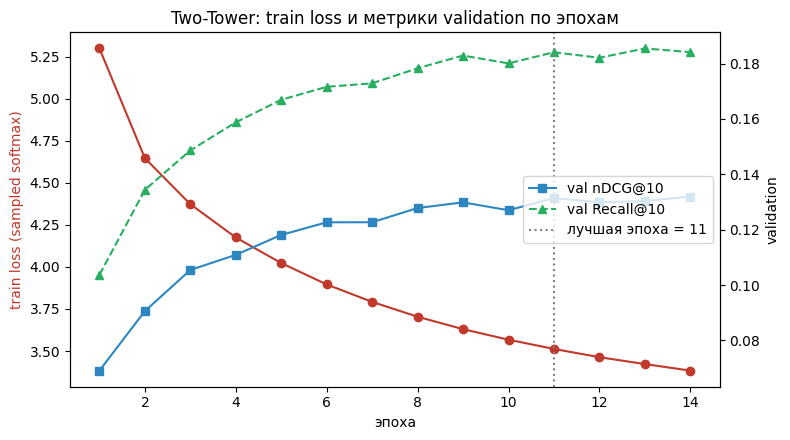

Лучшая эпоха (используется при переобучении на train+val): 11


In [10]:
tt_users = E.sample_eval_users(rel_val, ctx_v, cfg.tt_val_users, cfg.random_state + 2)
with timer("Two-Tower с признаками: обучение на train, early stopping по validation"):
    tt_v = TwoTowerScorer(cfg, use_features=True).fit(
        ctx_v, val_rel=rel_val, val_users=tt_users, save_path=cfg.models_dir / "two_tower_val_best.pt")
params.tt_epochs = tt_v.best_epoch
hist = tt_v.history_frame()
display(hist)
P.tt_history(hist, FIG / "two_tower_training.png", "Two-Tower: train loss и метрики validation по эпохам")
plt.show()
print("Лучшая эпоха (используется при переобучении на train+val):", params.tt_epochs)

Train loss монотонно падает, а метрики validation растут и выходят на плато. Модель действительно обучается, а early stopping останавливает её, когда качество на validation перестаёт расти.

**Ablation: нужны ли признаки в башнях?** Обучим ту же архитектуру только на ID-эмбеддингах (тот же seed, тот же early stopping) и сравним на одних и тех же validation-пользователях, в том числе по сегментам.

In [11]:
with timer("Two-Tower ID-only (ablation)"):
    tt_id = TwoTowerScorer(cfg, use_features=False, verbose=False).fit(ctx_v, val_rel=rel_val, val_users=tt_users)
rows = {}
seg_of = ctx_v.user_feats["segment"].to_numpy()
for label, model in [("Two-Tower: ID + признаки", tt_v), ("Two-Tower: только ID", tt_id)]:
    row = {"best_epoch": model.best_epoch}
    for seg in ["all", "short", "medium", "active"]:
        us = tune_users if seg == "all" else tune_users[seg_of[tune_users] == seg]
        row[f"nDCG@10 {seg}"] = PL.full_catalog_metrics(model, ctx_v, us, rel_val)["nDCG@10"]
    rows[label] = row
tt_ablation = pd.DataFrame(rows).T
display(tt_ablation)
tt_ablation.to_csv(RES / "val_two_tower_ablation.csv")
tt_v._cache_embeddings()

[Two-Tower ID-only (ablation)] 411.5 c


,best_epoch,nDCG@10 all,nDCG@10 short,nDCG@10 medium,nDCG@10 active
Two-Tower: ID + признаки,11.0000,0.1258,0.1066,0.1428,0.1226
Two-Tower: только ID,17.0000,0.1113,0.0905,0.1262,0.1142


## 6. Гибридная система

```
           ┌────────────┬────────────┬────────────┬────────────┬────────────┬────────────┐
 генераторы│ Popularity │ Content    │ Item-CF    │ SVD (Funk) │ PureSVD    │ Two-Tower  │  top-50 каждой модели,
           └─────┬──────┴─────┬──────┴─────┬──────┴─────┬──────┴─────┬──────┴─────┬──────┘  прочитанное исключено
                 └────────────┴────────────┴─────┬──────┴────────────┴────────────┘
                                         общий пул кандидатов (≈ 211 книг)
                                                 │  score всех сигналов: pop, cb, icf, svd, psvd, author, topic, tt
                                                 ▼
                         z-нормализация каждого сигнала по каталогу (для каждого пользователя)
                                                 ▼
                score = Σ w_seg(s) · z_s ;  веса w_seg — свои для short / medium / active (подбор на validation)
                                                 ▼
                    MMR-переранжирование top-50: λ·rel − (1−λ)·max sim  (λ подбирается на validation)
                                                 ▼
                                   top-K рекомендаций   (новый пользователь → cold-start стратегия)
```

* **Пул кандидатов.** Каждый генератор выбирает top-50 по всему каталогу непрочитанных книг. Объединение шести генераторов в среднем содержит ≈ 211 книг на пользователя (вывод `avg_pool_size` для validation и test ниже). Каждый вариант гибрида ранжирует только книги пула, пришедшие от его генераторов: классические гибриды — от пяти классических моделей, варианты +TT — от всех шести, Hybrid-Switch — от Popularity, CB и SVD. Score всех сигналов при этом считается для каждой книги пула.
* **Нормализация.** Сигналы имеют разные шкалы: рейтинг 1–5, косинус, сумма сходств. Для каждого пользователя score сигнала переводится в z-score по всем непрочитанным книгам каталога. Нормированный score не зависит от состава пула, поэтому одни и те же веса применимы и к пулу, и к внешнему набору кандидатов (протокол HW1).
* **Веса** ищутся случайным поиском по симплексу (Dirichlet) с локальным уточнением. Цель — средний nDCG@10 на validation.
* **Активность пользователя.** Отдельный набор весов для каждого сегмента: так короткая история может опираться на другие сигналы, чем длинная.
* **Баланс релевантности и разнообразия** — MMR по косинусу контентных эмбеддингов. λ выбирается заранее зафиксированным правилом: минимальная λ, при которой nDCG@10 на validation падает не более чем на 3 %.
* **Баланс персонализации и популярности** — вес `pop` в смеси, подбираемый для каждого сегмента. Отдельно анализируется кривая `score = (1−α)·персональный + α·популярность`.

Лесенка вариантов (каждый следующий добавляет один элемент; помогает ли он, проверяется на test в разделе 7.2):

| Вариант | Сигналы | Веса | MMR |
|---|---|---|---|
| Hybrid-Switch (HW1) | pop / cb / svd по длине истории | правило | нет |
| Hybrid-Weighted (**базовый гибрид**) | 5 классических моделей | глобальные | нет |
| Hybrid-Weighted+F | + признаки взаимодействий author, topic | глобальные | нет |
| Hybrid-Segment | + веса по сегментам | по сегментам | нет |
| Hybrid-Improved (**улучшенный классический гибрид**) | как Segment | по сегментам | да |
| Hybrid-Weighted+TT | 5 классических + Two-Tower | глобальные | нет |
| Hybrid-Segment+TT | + author, topic, сегменты | по сегментам | нет |
| Hybrid-Improved+TT (**улучшенный гибрид с Two-Tower**) | как Segment+TT | по сегментам | да |

In [12]:
sc_v["tt"] = tt_v
val_users = E.sample_eval_users(rel_val, ctx_v, cfg.n_val_users, cfg.random_state + 3)
with timer(f"Пул кандидатов validation ({len(val_users)} пользователей)"):
    pool_v = H.build_pool(ctx_v, sc_v, val_users, rel_val, PL.ALL_GENERATORS, cfg.candidates_per_model)
print("Сегменты validation-пользователей:", pd.Series(pool_v.segment).value_counts().to_dict())
cr_v = E.candidate_recall(pool_v)
cr_v["generator"] = cr_v["generator"].map(lambda g: Mo.MODEL_TITLES.get(g, g))
display(cr_v)

[Пул кандидатов validation (10000 пользователей)] 20.1 c
Сегменты validation-пользователей: {'medium': 4316, 'short': 3186, 'active': 2498}


,generator,recall_of_pool,avg_pool_size,unique_hits_share
0,union (pool),0.5387,211.3247,NaN
1,Popularity,0.0069,NaN,0.0032
2,Content-Based,0.2792,NaN,0.0425
3,Item-Based CF,0.3927,NaN,0.0789
4,"SVD (Funk, HW1)",0.0065,NaN,0.0025
5,"SVD (PureSVD, top-N)",0.3669,NaN,0.0679
6,Two-Tower,0.3313,NaN,0.0765


`recall_of_pool` — доля всех релевантных validation-книг, попавших в пул от генератора. `unique_hits_share` — доля попаданий пула, которые принёс *только* этот генератор. Объединение генераторов покрывает больше релевантных книг, чем любой генератор по отдельности: в этом смысл общего пула.

[Hybrid-Weighted: глобальные веса] 22.3 c


[Hybrid-Weighted+F: + признаки взаимодействий] 26.0 c


[Hybrid-Segment: веса по сегментам + признаки взаимодействий] 50.9 c


[Hybrid-Weighted+TT] 24.6 c


[Hybrid-Segment+TT] 54.3 c


...

,Popularity,Content-Based,Item-Based CF,"SVD (Funk, HW1)","SVD (PureSVD, top-N)",Author affinity,Topic affinity
short,0.4510,0.3390,0.2100,0.0000,0.0000,0.0010,0.0000
medium,0.1840,0.2430,0.4810,0.0010,0.0210,0.0710,0.0000
active,0.1890,0.0000,0.2260,0.2310,0.2480,0.0310,0.0760


Hybrid-Weighted+TT


,Popularity,Content-Based,Item-Based CF,"SVD (Funk, HW1)","SVD (PureSVD, top-N)",Two-Tower
все пользователи,0.0410,0.1520,0.0810,0.0000,0.0000,0.7260


Hybrid-Segment+TT


,Popularity,Content-Based,Item-Based CF,"SVD (Funk, HW1)","SVD (PureSVD, top-N)",Author affinity,Topic affinity,Two-Tower
short,0.0590,0.0960,0.0350,0.0000,0.0000,0.0000,0.0030,0.8070
medium,0.0000,0.0370,0.0740,0.0020,0.0000,0.0010,0.0000,0.8870
active,0.0180,0.1070,0.0890,0.0810,0.1590,0.0210,0.0280,0.4970


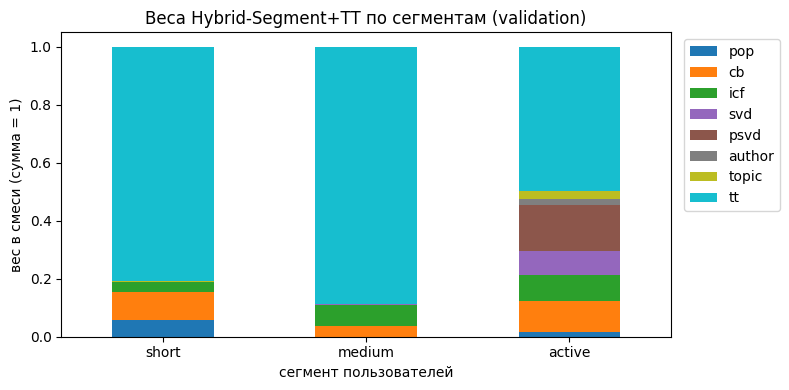

In [13]:
with timer("Подбор весов гибрида и λ MMR на validation"):
    variants, weight_logs, mmr_tables = PL.tune_hybrids(pool_v, ctx_v, cfg)

def weights_frame(v):
    if v.per_segment:
        return pd.DataFrame({k: w for k, w in v.weights.items() if k in ("short", "medium", "active")}).T
    return pd.DataFrame([v.weights], index=["все пользователи"])

for name in ["Hybrid-Weighted", "Hybrid-Weighted+F", "Hybrid-Segment", "Hybrid-Weighted+TT", "Hybrid-Segment+TT"]:
    print(name)
    display(weights_frame(variants[name]).rename(columns=Mo.MODEL_TITLES).round(3))
P.weights_bars(variants["Hybrid-Segment+TT"].weights, "Веса Hybrid-Segment+TT по сегментам (validation)",
               FIG / "hybrid_weights_by_segment.png")
plt.show()

In [14]:
val_cmp, val_per_user, _ = PL.evaluate_variants(pool_v, PL.comparison_variants(variants), ctx_v, cfg)
print("Validation (оптимистично: веса подобраны на этих же данных; финальные выводы — по test):")
display(val_cmp[["nDCG@5", "Recall@5", "nDCG@10", "Recall@10", "ILD@10", "Coverage@10"]])

Validation (оптимистично: веса подобраны на этих же данных; финальные выводы — по test):


,nDCG@5,Recall@5,nDCG@10,Recall@10,ILD@10,Coverage@10
model,,,,,,
Popularity,0.0005,0.0005,0.0007,0.0012,0.5269,0.0017
Content-Based,0.1025,0.1204,0.1170,0.1637,0.2169,0.8925
Item-Based CF,0.1514,0.1685,0.1696,0.2254,0.4279,0.9381
"SVD (Funk, HW1)",0.0005,0.0007,0.0007,0.0011,0.6266,0.0194
"SVD (PureSVD, top-N)",0.0900,0.0989,0.1069,0.1525,0.3212,0.6697
Two-Tower,0.1134,0.1326,0.1305,0.1852,0.4485,0.9722
Hybrid-Switch (HW1),0.0286,0.0404,0.0318,0.0501,0.5101,0.6637
Hybrid-Weighted,0.1544,0.1730,0.1727,0.2304,0.3689,0.9466
Hybrid-Weighted+F,0.1543,0.1726,0.1732,0.2312,0.3748,0.9464


### 6.1 Баланс релевантности и разнообразия (MMR)

Для каждой λ считаем на validation релевантность (nDCG@10, Recall@10) и разнообразие:

* ILD@10 — средняя попарная контентная непохожесть книг в списке;
* AuthorDiv@10 — доля уникальных авторов;
* Coverage@10 — доля каталога, попавшая в рекомендации;
* Novelty@10 — средняя самоинформация $-\log_2 p(i)$.

`overlap_with_lambda1` — доля книг, совпадающих со списком без MMR. Она показывает, насколько балансировка реально меняет выдачу.

Hybrid-Segment → выбранная λ = 0.6


,lambda,nDCG@10,Recall@10,ILD@10,AuthorDiv@10,Coverage@10,Novelty@10,overlap_with_lambda1,chosen
0,1.0000,0.1745,0.2331,0.3704,0.5900,0.9396,9.7133,1.0000,False
1,0.9000,0.1746,0.2322,0.4014,0.6055,0.9423,9.7140,0.9545,False
2,0.8000,0.1748,0.2324,0.4423,0.6289,0.9430,9.7148,0.9003,False
3,0.7000,0.1736,0.2294,0.4923,0.6578,0.9480,9.7158,0.8345,False
4,0.6000,0.1710,0.2262,0.5511,0.6980,0.9515,9.7172,0.7550,True
5,0.5000,0.1626,0.2173,0.6050,0.7455,0.9533,9.7191,0.6680,False
6,0.4000,0.1534,0.2040,0.6408,0.7935,0.9543,9.7209,0.5794,False
7,0.3000,0.1449,0.1901,0.6635,0.8362,0.9578,9.7228,0.4930,False


Hybrid-Segment+TT → выбранная λ = 0.6


,lambda,nDCG@10,Recall@10,ILD@10,AuthorDiv@10,Coverage@10,Novelty@10,overlap_with_lambda1,chosen
0,1.0000,0.1802,0.2421,0.3564,0.6324,0.9426,9.7173,1.0000,False
1,0.9000,0.1803,0.2417,0.3820,0.6454,0.9459,9.7177,0.9609,False
2,0.8000,0.1799,0.2405,0.4206,0.6639,0.9494,9.7186,0.9096,False
3,0.7000,0.1789,0.2387,0.4696,0.6904,0.9499,9.7194,0.8454,False
4,0.6000,0.1756,0.2337,0.5270,0.7260,0.9535,9.7205,0.7655,True
5,0.5000,0.1678,0.2259,0.5804,0.7690,0.9556,9.7219,0.6758,False
6,0.4000,0.1577,0.2123,0.6187,0.8161,0.9610,9.7236,0.5801,False
7,0.3000,0.1458,0.1901,0.6432,0.8609,0.9622,9.7257,0.4839,False


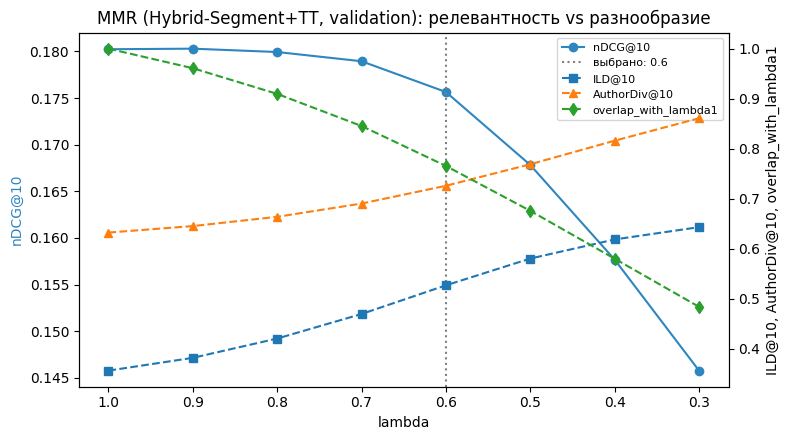

In [15]:
for base, table in mmr_tables.items():
    print(base, "→ выбранная λ =", table.loc[table["chosen"], "lambda"].iat[0])
    display(table)
    table.to_csv(RES / f"val_mmr_{base}.csv", index=False)
mt = mmr_tables["Hybrid-Segment+TT"]
P.tradeoff(mt, "lambda", "nDCG@10", ["ILD@10", "AuthorDiv@10", "overlap_with_lambda1"],
           "MMR (Hybrid-Segment+TT, validation): релевантность vs разнообразие",
           FIG / "mmr_tradeoff.png", chosen=variants["Hybrid-Improved+TT"].mmr_lambda)
plt.gca().invert_xaxis(); plt.show()

### 6.2 Баланс персонализации и популярности

Персональная часть — веса Hybrid-Segment+TT без `pop`, к ней подмешивается z-score популярности с весом α.

,alpha_pop,nDCG@10,Recall@10,Novelty@10,AvgPopPct@10,Coverage@10,Gini@10
0,0.0000,0.1802,0.2423,9.7172,0.5047,0.9446,0.4399
1,0.0500,0.1799,0.2415,9.7174,0.5046,0.9419,0.4477
2,0.1000,0.1795,0.2406,9.7174,0.5046,0.9350,0.4593
3,0.2000,0.1782,0.2393,9.7172,0.5054,0.9143,0.4910
4,0.3000,0.1755,0.2356,9.7167,0.5065,0.8789,0.5409
5,0.5000,0.1581,0.2103,9.7088,0.5204,0.7436,0.7154
6,0.7000,0.0911,0.1142,9.6596,0.6147,0.3607,0.9526
7,1.0000,0.0007,0.0012,9.5952,0.7464,0.0017,0.9990


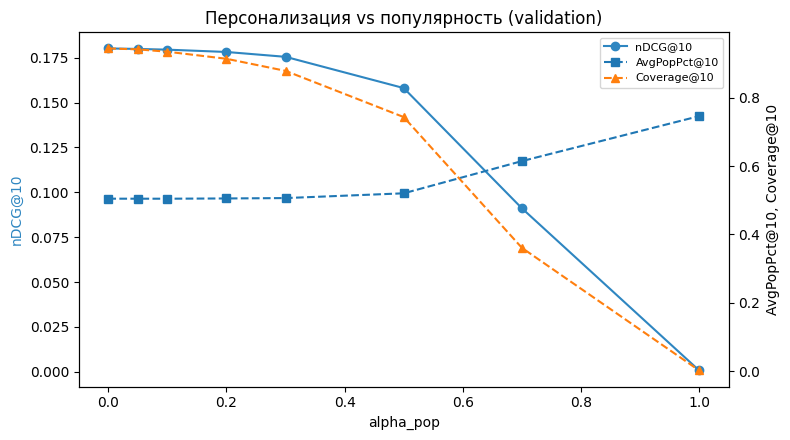

In [16]:
pop_tr = PL.popularity_tradeoff(pool_v, variants["Hybrid-Segment+TT"], ctx_v, cfg)
display(pop_tr)
pop_tr.to_csv(RES / "val_popularity_tradeoff.csv", index=False)
P.tradeoff(pop_tr, "alpha_pop", "nDCG@10", ["AvgPopPct@10", "Coverage@10"],
           "Персонализация vs популярность (validation)", FIG / "popularity_tradeoff.png")
plt.show()

### 6.3 Новые пользователи (cold start): выбор стратегии на validation

Для нового пользователя нет истории, поэтому `cb`, `icf`, `psvd`, `author`, `topic` и ID-эмбеддинг недоступны. Симулируем это на validation-пользователях: скрываем историю и ранжируем каталог только неперсональными сигналами. Это варианты Popularity и вектор «нового пользователя» Two-Tower, который строится по ID 0 и усреднённым признакам. Стратегия выбирается здесь, на test она только проверяется.

In [17]:
cold_val = PL.cold_start_experiment(ctx_v, sc_v, rel_val, val_users[:3000], cfg)
display(cold_val)
pop_name = f"Popularity ({params.pop_kind})"
tt_name = "Two-Tower (вектор нового пользователя)"
new_user_strategy = "tt" if cold_val.loc[tt_name, "nDCG@10"] > cold_val.loc[pop_name, "nDCG@10"] else "pop"
print("Стратегия для новых пользователей (выбрана на validation):", new_user_strategy)

,Precision@10,Recall@10,nDCG@10,Coverage@10
model,,,,
Popularity (weighted_rating),0.0006,0.0025,0.0014,0.0017
Popularity (n_ratings),0.0001,0.0002,0.0002,0.0015
Popularity (share_pos),0.0003,0.0008,0.0005,0.0012
Two-Tower (вектор нового пользователя),0.0002,0.0002,0.0002,0.0013
Random,0.0002,0.0008,0.0006,0.9512


Стратегия для новых пользователей (выбрана на validation): pop


## 7. Финальная оценка на test

Все гиперпараметры, веса, λ и число эпох Two-Tower зафиксированы на validation. Модели и признаки **переобучаются на `train_full = train + validation`**; test используется только как ground truth.

**Основной протокол — full-catalog candidate generation + pooled hybrid ranking.** Оценка проводится на 10 000 случайных test-пользователях, у каждого есть хотя бы одна релевантная test-книга. Гибриды работают в двухэтапной архитектуре:

1. **Генерация кандидатов.** Каждая модель-генератор (Popularity, CB, Item-CF, Funk SVD, PureSVD, Two-Tower) ранжирует весь каталог без книг, прочитанных в `train_full`, и отдаёт свой top-50. Объединение образует пул кандидатов: в среднем ≈ 211 книг на пользователя (`avg_pool_size` в выводе ниже).
2. **Объединение score и финальное ранжирование.** Для каждой книги пула берутся z-нормализованные score всех сигналов, они смешиваются с весами варианта и при необходимости переранжируются MMR. Top-K выбирается внутри пула, причём каждый гибрид использует только книги от своих генераторов.

**Одиночные модели оцениваются на кандидатах из полного каталога.** Одиночная модель ранжирует внутри пула только собственный top-50, поэтому её top-K совпадает с top-K по всему каталогу непрочитанных книг. Гибриды каталог целиком не ранжируют: книга, которую не выбрал ни один из их генераторов, в выдачу попасть не может.

Релевантные test-книги **не добавляются** в пул искусственно: test используется только для разметки уже отобранных кандидатов и подсчёта метрик. Precision@K, Recall@K и nDCG@K считаются относительно **всех** фактических test-релевантных книг пользователя (`rating ≥ 4`), включая не попавшие в пул: Precision@K = попадания / K, Recall@K = попадания / число релевантных, идеальный DCG — по min(число релевантных, K). Релевантная книга вне пула снижает Recall и nDCG гибрида. Подпись «full-catalog» в таблицах и на графиках ниже — краткое название этого протокола.

In [18]:
ctx_t = Mo.fit_context(s.train_full, prep.index, prep.catalog, cfg)   # признаки этапа test: только train_full
rel_test = E.relevance_matrix(s.test, prep.index, cfg.relevance_threshold)
with timer("Переобучение всех моделей на train_full"):
    sc_t = PL.fit_classic_scorers(ctx_t, params, cfg)
    sc_t["tt"] = TwoTowerScorer(cfg, use_features=True).fit(
        ctx_t, n_epochs=params.tt_epochs, save_path=cfg.models_dir / "two_tower_final.pt")
PL.save_artifacts(cfg, params, variants, sc_t)
assert sc_t["svd"].algo.trainset.n_ratings == len(s.train_full)
assert ctx_t.R.nnz == len(s.train_full)

[Popularity] 0.0 c
[Content-Based] 0.0 c


[Item-Based CF (top-k соседей, батчами)] 1.5 c


[SVD (Funk, surprise)] 9.4 c


[PureSVD] 12.8 c


epoch  1 loss=5.2544 (21.6s)


...

epoch  7 loss=3.8178 (20.7s)


epoch  8 loss=3.7404 (20.4s)


epoch  9 loss=3.6760 (20.1s)


epoch 10 loss=3.6199 (20.4s)


epoch 11 loss=3.5727 (20.9s)
[Переобучение всех моделей на train_full] 276.6 c


In [19]:
test_users = E.sample_eval_users(rel_test, ctx_t, cfg.n_test_users, cfg.random_state + 4)
with timer(f"Пул кандидатов test ({len(test_users)} пользователей)"):
    pool_t = H.build_pool(ctx_t, sc_t, test_users, rel_test, PL.ALL_GENERATORS, cfg.candidates_per_model)
print("Сегменты test-пользователей:", pd.Series(pool_t.segment).value_counts().to_dict())
cr_t = E.candidate_recall(pool_t)
cr_t["generator"] = cr_t["generator"].map(lambda g: Mo.MODEL_TITLES.get(g, g))
display(cr_t)

all_variants = PL.comparison_variants(variants)
summary, per_user, tops = PL.evaluate_variants(pool_t, all_variants, ctx_t, cfg)
summary.to_csv(RES / "test_full_catalog.csv")
REL = ["Precision@5", "Recall@5", "nDCG@5", "Precision@10", "Recall@10", "nDCG@10"]
DIV = ["ILD@10", "AuthorDiv@10", "Novelty@10", "AvgPopPct@10", "Coverage@10", "Gini@10"]
print("ИТОГОВАЯ ТАБЛИЦА (test, full-catalog): релевантность")
display(summary[REL].style.format("{:.4f}").highlight_max(axis=0, color="#d4efdf"))
print("Разнообразие и покрытие")
display(summary[DIV].style.format("{:.4f}"))

[Пул кандидатов test (10000 пользователей)] 16.1 c
Сегменты test-пользователей: {'short': 3743, 'medium': 3630, 'active': 2627}


,generator,recall_of_pool,avg_pool_size,unique_hits_share
0,union (pool),0.5752,210.7817,NaN
1,Popularity,0.0067,NaN,0.0022
2,Content-Based,0.2941,NaN,0.0340
3,Item-Based CF,0.4288,NaN,0.0745
4,"SVD (Funk, HW1)",0.0074,NaN,0.0023
5,"SVD (PureSVD, top-N)",0.4066,NaN,0.0647
6,Two-Tower,0.3756,NaN,0.0731


ИТОГОВАЯ ТАБЛИЦА (test, full-catalog): релевантность


,Precision@5,Recall@5,nDCG@5,Precision@10,Recall@10,nDCG@10
model,,,,,,
Popularity,0.0004,0.0009,0.0007,0.0004,0.0012,0.0008
Content-Based,0.0633,0.1380,0.1274,0.0448,0.1836,0.1401
Item-Based CF,0.1025,0.1995,0.1991,0.0710,0.2569,0.2123
"SVD (Funk, HW1)",0.0004,0.0005,0.0006,0.0004,0.0015,0.0009
"SVD (PureSVD, top-N)",0.0759,0.1105,0.1169,0.0573,0.1657,0.1301
Two-Tower,0.0819,0.1697,0.1605,0.0582,0.2236,0.1746
Hybrid-Switch (HW1),0.0113,0.0551,0.0415,0.0074,0.0708,0.0465
Hybrid-Weighted,0.1032,0.2030,0.2022,0.0717,0.2647,0.2167
Hybrid-Weighted+F,0.1032,0.2024,0.2019,0.0718,0.2627,0.2161


Разнообразие и покрытие


,ILD@10,AuthorDiv@10,Novelty@10,AvgPopPct@10,Coverage@10,Gini@10
model,,,,,,
Popularity,0.3698,0.3012,9.3484,0.6586,0.0019,0.9990
Content-Based,0.2175,0.6503,9.4260,0.4715,0.8867,0.5829
Item-Based CF,0.4301,0.6577,9.4272,0.4799,0.9239,0.5006
"SVD (Funk, HW1)",0.5939,0.5353,9.4205,0.4788,0.0198,0.9980
"SVD (PureSVD, top-N)",0.3162,0.5458,9.3711,0.5808,0.6857,0.7199
Two-Tower,0.4455,0.8079,9.4464,0.4453,0.9700,0.4352
Hybrid-Switch (HW1),0.4643,0.5995,9.4338,0.4623,0.6587,0.8905
Hybrid-Weighted,0.3633,0.6323,9.4306,0.4746,0.9407,0.4609
Hybrid-Weighted+F,0.3696,0.6113,9.4298,0.4761,0.9389,0.4591


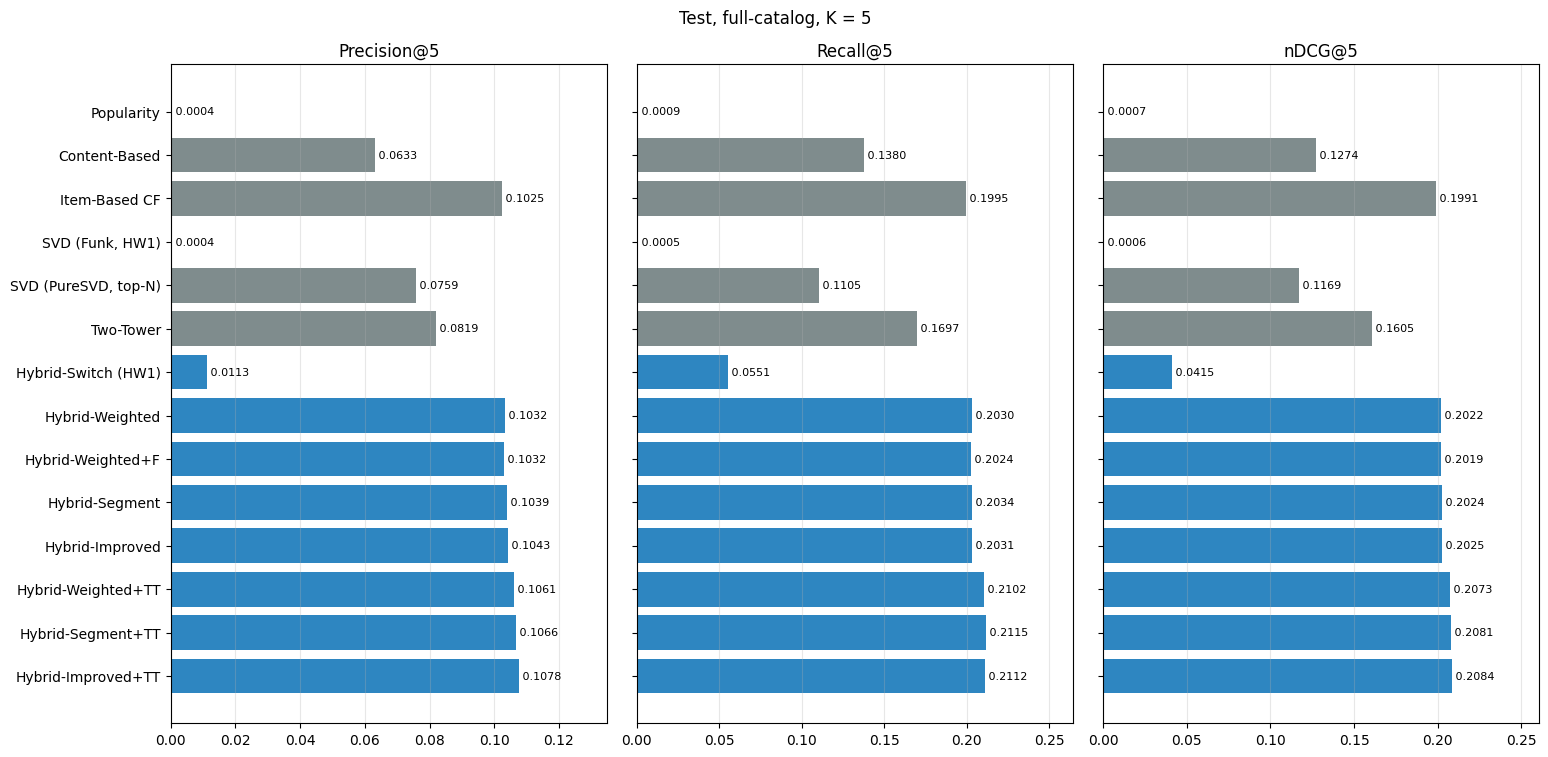

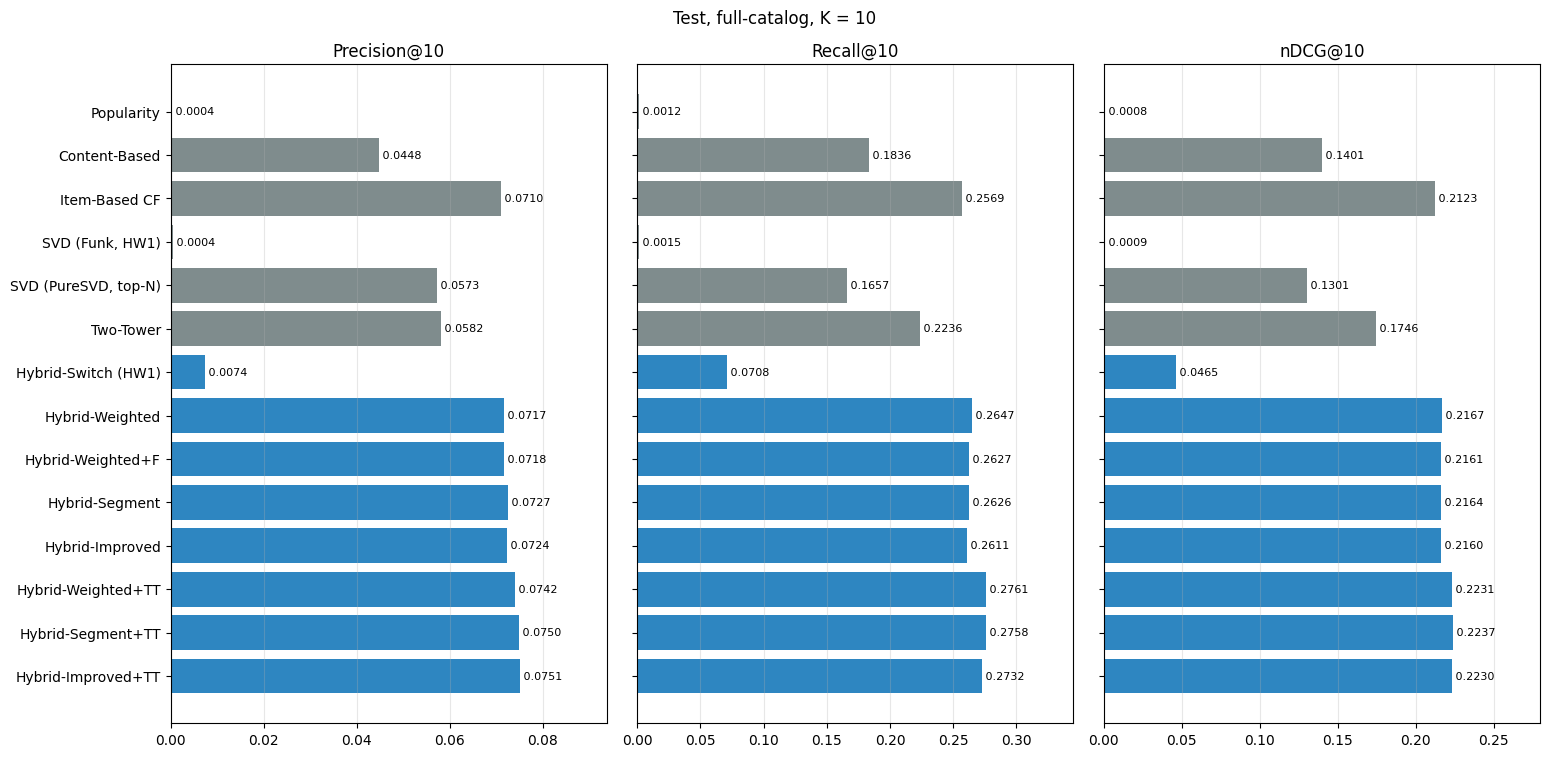

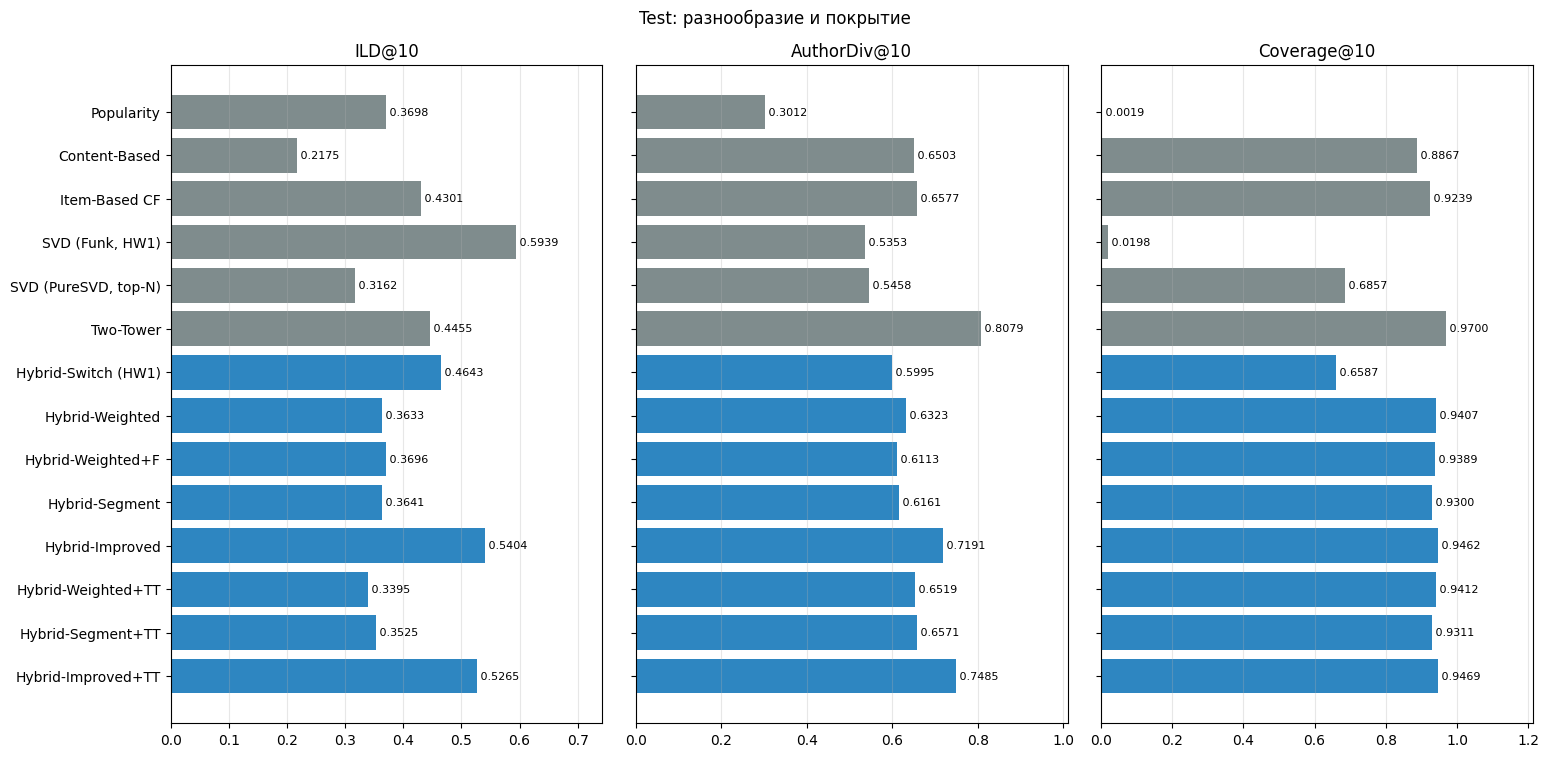

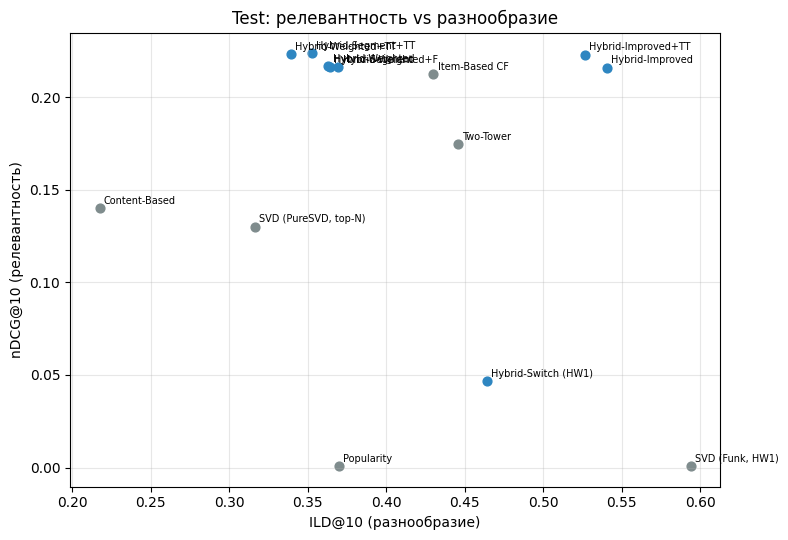

In [20]:
P.metric_bars(summary, ["Precision@5", "Recall@5", "nDCG@5"], "Test, full-catalog, K = 5", FIG / "test_metrics_k5.png")
plt.show()
P.metric_bars(summary, ["Precision@10", "Recall@10", "nDCG@10"], "Test, full-catalog, K = 10", FIG / "test_metrics_k10.png")
plt.show()
P.metric_bars(summary, ["ILD@10", "AuthorDiv@10", "Coverage@10"], "Test: разнообразие и покрытие", FIG / "test_diversity.png")
plt.show()

fig, ax = plt.subplots(figsize=(8, 5.5))
for name, row in summary.iterrows():
    ax.scatter(row["ILD@10"], row["nDCG@10"], color=P.PALETTE[row["group"]], s=40)
    ax.annotate(name, (row["ILD@10"], row["nDCG@10"]), fontsize=7, xytext=(3, 3), textcoords="offset points")
ax.set_xlabel("ILD@10 (разнообразие)"); ax.set_ylabel("nDCG@10 (релевантность)")
ax.set_title("Test: релевантность vs разнообразие"); ax.grid(alpha=0.3)
fig.tight_layout(); fig.savefig(FIG / "test_relevance_vs_diversity.png", dpi=120); plt.show()

### 7.1 Анализ по сегментам пользователей

Пользователей в сегментах: {'short': 3743, 'medium': 3630, 'active': 2627}
nDCG@10 по сегментам (test):


segment,short,medium,active,all
Popularity,0.0002,0.0013,0.0010,0.0008
Content-Based,0.1366,0.1370,0.1495,0.1401
Item-Based CF,0.1767,0.2128,0.2625,0.2123
"SVD (Funk, HW1)",0.0008,0.0005,0.0017,0.0009
"SVD (PureSVD, top-N)",0.0587,0.1361,0.2238,0.1301
Two-Tower,0.1693,0.1656,0.1947,0.1746
Hybrid-Switch (HW1),0.1227,0.0005,0.0017,0.0465
Hybrid-Weighted,0.1870,0.2136,0.2633,0.2167
Hybrid-Weighted+F,0.1853,0.2132,0.2639,0.2161
Hybrid-Segment,0.1851,0.2132,0.2653,0.2164


Recall@5 по сегментам (test):


segment,short,medium,active,all
Popularity,0.0005,0.0017,0.0005,0.0009
Content-Based,0.1624,0.1407,0.0993,0.1380
Item-Based CF,0.2063,0.2169,0.1658,0.1995
"SVD (Funk, HW1)",0.0008,0.0000,0.0008,0.0005
"SVD (PureSVD, top-N)",0.0671,0.1364,0.1367,0.1105
Two-Tower,0.2022,0.1716,0.1208,0.1697
Hybrid-Switch (HW1),0.1467,0.0000,0.0008,0.0551
Hybrid-Weighted,0.2159,0.2162,0.1666,0.2030
Hybrid-Weighted+F,0.2132,0.2173,0.1663,0.2024
Hybrid-Segment,0.2172,0.2173,0.1644,0.2034


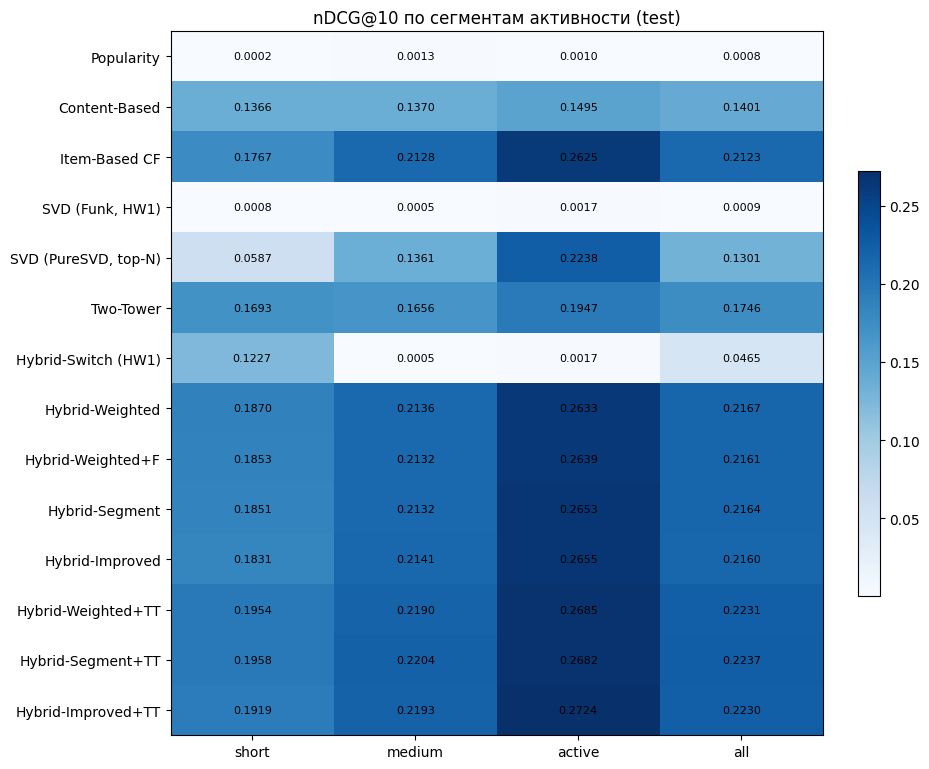

Относительная разница Hybrid-Improved+TT vs лучшая одиночная модель (Item-Based CF), %:


segment,short,medium,active,all
"Δ nDCG@10, %",8.6000,3.0000,3.8000,5.0000


In [21]:
seg_ndcg = E.segment_table(per_user, "nDCG@10")
seg_rec5 = E.segment_table(per_user, "Recall@5")
seg_ndcg.to_csv(RES / "test_segments_ndcg10.csv")
print("Пользователей в сегментах:", pd.Series(pool_t.segment).value_counts().reindex(["short", "medium", "active"]).to_dict())
print("nDCG@10 по сегментам (test):")
display(seg_ndcg.style.format("{:.4f}").highlight_max(axis=0, color="#d4efdf"))
print("Recall@5 по сегментам (test):")
display(seg_rec5.style.format("{:.4f}").highlight_max(axis=0, color="#d4efdf"))
P.segment_heatmap(seg_ndcg, "nDCG@10 по сегментам активности (test)", FIG / "test_segments_heatmap.png")
plt.show()

best_single = summary[summary["group"] == "model"]["nDCG@10"].idxmax()
rel_gain = (seg_ndcg.loc["Hybrid-Improved+TT"] / seg_ndcg.loc[best_single] - 1) * 100
print(f"Относительная разница Hybrid-Improved+TT vs лучшая одиночная модель ({best_single}), %:")
display(rel_gain.round(1).to_frame("Δ nDCG@10, %").T)

### 7.2 Статистическая значимость различий

Paired bootstrap по пользователям (1000 повторов): 95 %-доверительный интервал разности средних метрик двух вариантов на одних и тех же test-пользователях. Разница считается значимой, если интервал не содержит 0. Интервалы описывают неопределённость оценки разности на этой выборке пользователей при один раз обученных моделях; вариативность обучения между random seeds в них не входит (см. 10.5).

In [22]:
pairs = [
    ("Hybrid-Weighted", best_single),
    ("Hybrid-Weighted+F", "Hybrid-Weighted"),
    ("Hybrid-Segment", "Hybrid-Weighted+F"),
    ("Hybrid-Improved", "Hybrid-Segment"),
    ("Hybrid-Weighted+TT", "Hybrid-Weighted"),
    ("Hybrid-Segment+TT", "Hybrid-Segment"),
    ("Hybrid-Improved+TT", "Hybrid-Improved"),
    ("Hybrid-Improved+TT", best_single),
    ("Two-Tower", best_single),
    ("Hybrid-Weighted", "Hybrid-Switch (HW1)"),
]
boot = pd.concat([PL.bootstrap_table(per_user, pairs, "nDCG@10", cfg),
                  PL.bootstrap_table(per_user, [("Hybrid-Improved+TT", "Hybrid-Segment+TT"),
                                                ("Hybrid-Improved", "Hybrid-Segment")], "ILD@10", cfg)],
                 ignore_index=True)
boot.to_csv(RES / "test_bootstrap.csv", index=False)
display(boot)

,A,B,metric,diff,ci_low,ci_high,p_value_two_sided,significant_95
0,Hybrid-Weighted,Item-Based CF,nDCG@10,0.0044,0.0030,0.0056,0.0000,True
1,Hybrid-Weighted+F,Hybrid-Weighted,nDCG@10,-0.0006,-0.0014,0.0002,0.1300,False
2,Hybrid-Segment,Hybrid-Weighted+F,nDCG@10,0.0003,-0.0007,0.0015,0.5520,False
3,Hybrid-Improved,Hybrid-Segment,nDCG@10,-0.0004,-0.0017,0.0010,0.5420,False
4,Hybrid-Weighted+TT,Hybrid-Weighted,nDCG@10,0.0064,0.0047,0.0081,0.0000,True
5,Hybrid-Segment+TT,Hybrid-Segment,nDCG@10,0.0073,0.0053,0.0091,0.0000,True
6,Hybrid-Improved+TT,Hybrid-Improved,nDCG@10,0.0070,0.0048,0.0090,0.0000,True
7,Hybrid-Improved+TT,Item-Based CF,nDCG@10,0.0106,0.0081,0.0130,0.0000,True
8,Two-Tower,Item-Based CF,nDCG@10,-0.0377,-0.0420,-0.0339,0.0000,True
9,Hybrid-Weighted,Hybrid-Switch (HW1),nDCG@10,0.1702,0.1648,0.1756,0.0000,True


### 7.3 Протокол HW_1_FINAL на том же test: воспроизведение и сравнение

Тот же отбор пользователей и негативов, что в HW1: 1000 пользователей, relevant + до 100 случайных негативов, seed 42, K = 5. Модели обучены на `train_full`, который совпадает с `train_df` HW1. Строки «(код HW1)» скорят кандидатов исходными функциями HW1 (для SVD — с параметрами HW1: 100 факторов, 20 эпох, `reg_all = 0.02`) и должны **воспроизвести** его таблицу. Остальные строки — модели и гибриды этого проекта на тех же candidate set; гибриды используют те же веса (z-нормализация по каталогу делает их применимыми к любому набору кандидатов).

[Протокол HW1] 29.2 c
Пользователей: 1000


,Precision@5,Recall@5,nDCG@5,Precision@5 (HW1),Recall@5 (HW1),nDCG@5 (HW1)
Popularity (код HW1),0.0324,0.0687,0.0530,0.0324,0.0687,0.0530
Item-Based CF (код HW1),0.0206,0.0471,0.0349,0.0206,0.0471,0.0349
SVD (код HW1),0.0318,0.0665,0.0508,0.0318,0.0665,0.0508
Popularity,0.0324,0.0687,0.0530,—,—,—
Content-Based,0.2626,0.5386,0.5311,—,—,—
Item-Based CF,0.2586,0.4334,0.4842,—,—,—
"SVD (Funk, HW1)",0.0310,0.0725,0.0546,—,—,—
"SVD (PureSVD, top-N)",0.3014,0.6038,0.5857,—,—,—
Two-Tower,0.2960,0.6190,0.5967,—,—,—
Hybrid-Switch (HW1),0.0642,0.2385,0.2021,—,—,—


Максимальное отклонение от таблицы HW_1_FINAL: 3.475802841379494e-07


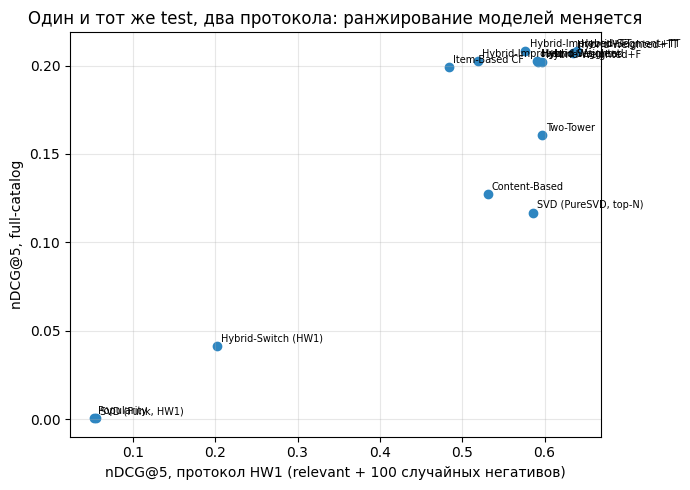

In [23]:
with timer("Протокол HW1"):
    sampled, sampled_per, n_sampled = PL.sampled_protocol(prep, ctx_t, sc_t, all_variants, cfg)
sampled.to_csv(RES / "test_sampled_hw1_protocol.csv")
print("Пользователей:", n_sampled)
display(sampled.style.format("{:.4f}", na_rep="—"))
repro = sampled.loc[[i for i in sampled.index if "(код HW1)" in i]]
diff = (repro[["Precision@5", "Recall@5", "nDCG@5"]].to_numpy()
        - repro[["Precision@5 (HW1)", "Recall@5 (HW1)", "nDCG@5 (HW1)"]].to_numpy())
print("Максимальное отклонение от таблицы HW_1_FINAL:", float(np.abs(diff).max()))

P.protocol_scatter(summary["nDCG@5"], sampled["nDCG@5"],
                   "Один и тот же test, два протокола: ранжирование моделей меняется", FIG / "protocol_comparison.png")
plt.show()

### 7.4 Cold start на test

Стратегия выбрана на validation (раздел 6.3), здесь только проверка на test-пользователях со скрытой историей.

In [24]:
cold_test = PL.cold_start_experiment(ctx_t, sc_t, rel_test, test_users[:3000], cfg)
cold_test.to_csv(RES / "test_cold_start.csv")
display(cold_test)
print("Стратегия, выбранная на validation:", new_user_strategy)

,Precision@10,Recall@10,nDCG@10,Coverage@10
model,,,,
Popularity (weighted_rating),0.0004,0.0017,0.0011,0.0019
Popularity (n_ratings),0.0001,0.0001,0.0001,0.0018
Popularity (share_pos),0.0005,0.0009,0.0007,0.0013
Two-Tower (вектор нового пользователя),0.0006,0.0008,0.0008,0.0013
Random,0.0002,0.0007,0.0007,0.9508


Стратегия, выбранная на validation: pop


## 8. Рекомендации через сервисный интерфейс

`H.HybridRecommender` — production-интерфейс итоговой системы. Он принимает `user_id` и проходит весь путь: определение сегмента → score всех моделей → z-нормализация → общий пул → смешивание с весами сегмента → MMR → top-N с названиями и «главным сигналом», который сильнее всего повлиял на позицию книги. Новый пользователь (ID нет в train) обслуживается cold-start стратегией.

In [25]:
final = variants["Hybrid-Improved+TT"]
recommender = H.HybridRecommender(ctx_t, sc_t, final.weights, final.generators, final.mmr_lambda,
                                  cfg.candidates_per_model, cfg.mmr_top_m, name=final.name,
                                  new_user_strategy=new_user_strategy)

# Проверка согласованности: сервисный интерфейс выдаёт то же, что пакетная оценка на пуле.
check_users = test_users[:200]
pos_in_test = {u: r for r, u in enumerate(pool_t.users)}
agree = []
for u in check_users:
    recs = recommender.recommend(int(prep.index.user_ids[u]), n=10)["book_id"].to_numpy() - 1
    agree.append(len(np.intersect1d(recs, tops[final.name][pos_in_test[u]])) / 10)
print(f"Совпадение сервисного top-10 с пакетной оценкой: {np.mean(agree):.3f}")

def show_user(user_id, n=10):
    uidx = prep.index.users_to_idx(np.array([user_id]))[0]
    recs = recommender.recommend(user_id, n=n)
    a = recs.attrs
    print(f"user_id={user_id} | сегмент={a['segment']} | история={a['n_history']} | веса: "
          + ", ".join(f"{k}={v:.2f}" for k, v in a["weights"].items() if v > 0.005))
    if uidx >= 0 and a["n_history"] > 0:
        hist = s.train_full[s.train_full["user_id"] == user_id].sort_values("rating", ascending=False).head(5)
        hist = hist.merge(prep.catalog.books[["id", "title"]], left_on="book_id", right_on="id")
        print("Любимые книги в истории:", "; ".join(f"{t} ({r:.0f})" for t, r in zip(hist["title"], hist["rating"])))
        test_rel = set(s.test.loc[(s.test["user_id"] == user_id) & (s.test["rating"] >= 4), "book_id"])
        recs["hit_in_test"] = recs["book_id"].isin(test_rel)
    display(recs)

seg_arr = ctx_t.user_feats["segment"].to_numpy()
for seg in ["short", "medium", "active"]:
    u = test_users[seg_arr[test_users] == seg][0]
    show_user(int(prep.index.user_ids[u]))
show_user(int(prep.index.user_ids.max()) + 1)   # новый пользователь

Совпадение сервисного top-10 с пакетной оценкой: 1.000
user_id=29 | сегмент=short | история=5 | веса: pop=0.06, cb=0.10, icf=0.03, tt=0.81
Любимые книги в истории: Homo Faber (5); On the Genealogy of Morals/Ecce Homo (4); Poetics (4); The History of Sexuality, Volume 1: An Introduction (3); On the Genealogy of Morals (3)


,rank,book_id,title,authors,topic,hybrid_score,main_signal,hit_in_test
0,1,9667,The Gay Science,Friedrich Nietzsche,classic,5.9250,tt,False
1,2,8840,Passing,Nella Larsen,classic,3.6950,tt,False
2,3,7444,Phenomenology of Spirit,Georg Wilhelm Friedrich Hegel,self-help,4.8060,tt,False
3,4,9311,Groundwork of the Metaphysics of Morals,Immanuel Kant,classic,4.5850,tt,False
4,5,9649,Ethics,Baruch Spinoza,classic,3.0700,tt,False
5,6,4880,Apology,Plato,classic,4.3170,tt,False
6,7,8472,Metaphysics,Aristotle,classic,4.4000,tt,False
7,8,9078,Orientalism,Edward Said,self-help,4.0700,tt,False
8,9,6272,Being and Time,Martin Heidegger,self-help,4.1240,tt,False
9,10,6896,"Five Dialogues: Euthyphro, Apology, Crito, Meno, Phaedo",Plato,classic,4.1280,tt,False


user_id=11 | сегмент=medium | история=8 | веса: cb=0.04, icf=0.07, tt=0.89
Любимые книги в истории: Arch of Triumph: A Novel of a Man Without a Country (5); Restless (4); Winter in Madrid (4); Everyman (4); Well-Schooled in Murder (Inspector Lynley, #3) (4)


,rank,book_id,title,authors,topic,hybrid_score,main_signal,hit_in_test
0,1,6055,Three Comrades,Erich Maria Remarque,historical,5.4590,tt,False
1,2,4231,"A Great Deliverance (Inspector Lynley, #1)",Elizabeth George,mystery-thriller,5.1090,icf,False
2,3,9804,"Heartstone (Matthew Shardlake, #5)",C.J. Sansom,historical,4.4560,tt,False
3,4,9240,Arthur & George,Julian Barnes,historical,4.2670,tt,False
4,5,7039,The Brothers Lionheart,Astrid Lindgren,children-s,3.3580,tt,False
5,6,5123,Shroud for a Nightingale (Adam Dalgliesh #4),P.D. James,mystery-thriller,4.5720,tt,False
6,7,8902,Hunting and Gathering,Anna Gavalda,literature,3.3780,tt,False
7,8,5421,Small Island,Andrea Levy,historical,2.9410,tt,False
8,9,8283,"Sovereign (Matthew Shardlake, #3)",C.J. Sansom,historical,4.3320,tt,False
9,10,6625,The Yacoubian Building,Alaa Al Aswany,literature,2.9370,tt,False


user_id=35 | сегмент=active | история=100 | веса: pop=0.02, cb=0.11, icf=0.09, svd=0.08, psvd=0.16, author=0.02, topic=0.03, tt=0.50
Любимые книги в истории: Outlander (Outlander, #1) (5); Into the Wilderness (Wilderness, #1) (5); We Wish to Inform You That Tomorrow We Will Be Killed with Our Families (4); Daughter of Fortune (4); The Boy Who Harnessed the Wind: Creating Currents of Electricity and Hope (4)


,rank,book_id,title,authors,topic,hybrid_score,main_signal,hit_in_test
0,1,782,The Awakening,Kate Chopin,classic,4.5860,icf,False
1,2,559,Tess of the D'Urbervilles,Thomas Hardy,literature,4.4430,icf,False
2,3,1970,Possession,A.S. Byatt,historical,3.8040,tt,False
3,4,664,Breakfast at Tiffany's,Truman Capote,literature,3.9840,icf,False
4,5,899,The Age of Innocence,Edith Wharton,literature,4.0350,tt,False
5,6,1094,My Ántonia,Willa Cather,classic,3.9110,tt,False
6,7,171,Emma,Jane Austen,historical,4.2120,icf,False
7,8,430,Kafka on the Shore,Haruki Murakami,literature,3.2290,tt,False
8,9,231,Sarah's Key,Tatiana de Rosnay,historical,3.0160,tt,False
9,10,864,"The Fiery Cross (Outlander, #5)",Diana Gabaldon,historical,3.1550,psvd,False


user_id=53425 | сегмент=new | история=0 | веса: pop=1.00


,rank,book_id,title,authors,topic,hybrid_score,main_signal
0,1,5580,The Calvin and Hobbes Lazy Sunday Book,Bill Watterson,comics-graphic-novels,3.0630,pop
1,2,9076,Preach My Gospel: A Guide To Missionary Service,The Church of Jesus Christ of Latter-day Saints,christian,2.9880,pop
2,3,1308,"A Court of Mist and Fury (A Court of Thorns and Roses, #2)",Sarah J. Maas,high-fantasy,2.9370,pop
3,4,4708,BookRags Summary: A Storm of Swords,BookRags,high-fantasy,2.9130,pop
4,5,3275,"Harry Potter Boxed Set, Books 1-5 (Harry Potter, #1-5)",J.K. Rowling,children-s,2.8200,pop
5,6,9566,Attack of the Deranged Mutant Killer Monster Snow Goons,Bill Watterson,comics-graphic-novels,3.0340,pop
6,7,6590,The Authoritative Calvin and Hobbes: A Calvin and Hobbes Treasury,Bill Watterson,comics-graphic-novels,3.0190,pop
7,8,8976,Rita Hayworth and Shawshank Redemption: A Story from Different Seasons,Stephen King,horror,2.5680,pop
8,9,8569,"Styxx (Dark-Hunter, #22)",Sherrilyn Kenyon,paranormal,2.5880,pop
9,10,8978,The Revenge of the Baby-Sat,Bill Watterson,comics-graphic-novels,2.9810,pop


In [26]:
# Влияние MMR на выдачу конкретного пользователя: λ = 1 (без MMR) против выбранной λ
u = test_users[seg_arr[test_users] == "active"][1]
uid = int(prep.index.user_ids[u])
recommender.mmr_lambda = 1.0
no_mmr = recommender.recommend(uid, 10)
recommender.mmr_lambda = final.mmr_lambda
with_mmr = recommender.recommend(uid, 10)
cmp = pd.DataFrame({"без MMR (λ=1)": no_mmr["title"].str[:45] + " — " + no_mmr["authors"],
                    f"MMR (λ={final.mmr_lambda})": with_mmr["title"].str[:45] + " — " + with_mmr["authors"]})
display(cmp)
print("Уникальных авторов:", no_mmr["authors"].nunique(), "→", with_mmr["authors"].nunique(),
      "| уникальных тем:", no_mmr["topic"].nunique(), "→", with_mmr["topic"].nunique())

,без MMR (λ=1),MMR (λ=0.6)
0,"Half a War (Shattered Sea, #3) — Joe Abercrombie","Half a War (Shattered Sea, #3) — Joe Abercrombie"
1,"Red Country (First Law World, #6) — Joe Abercrombie",The Marriage Plot — Jeffrey Eugenides
2,This is Where I Leave You — Jonathan Tropper,This is Where I Leave You — Jonathan Tropper
3,The Marriage Plot — Jeffrey Eugenides,"Red Country (First Law World, #6) — Joe Abercrombie"
4,"Last Argument of Kings (The First Law, #3) — Joe Abercrombie",When Breath Becomes Air — Paul Kalanithi
5,Best Served Cold — Joe Abercrombie,The Orphan Master's Son — Adam Johnson
6,"The Heroes (First Law World, #5) — Joe Abercrombie",The Age of Miracles — Karen Thompson Walker
7,"The Lies of Locke Lamora (Gentleman Bastard, — Scott Lynch",Yes Please — Amy Poehler
8,Before They Are Hanged (The First Law #2) — Joe Abercrombie,Commonwealth — Ann Patchett
9,Yes Please — Amy Poehler,"Last Argument of Kings (The First Law, #3) — Joe Abercrombie"


Уникальных авторов: 5 → 8 | уникальных тем: 4 → 6


## 9. Сквозной пайплайн и артефакты

Весь процесс, показанный в ноутбуке, оформлен как воспроизводимый пайплайн `recsys/pipeline.py`:

**Загрузка** (`load_raw`, из zip) → **проверки** (`validate_raw`, assert-ы схем и ID) → **очистка** (`clean_ratings`) → **разбиение** (`make_splits` + `check_no_leakage`) → **признаки** (`build_catalog`, `fit_context`) → **обучение моделей** (`tune_components`, `fit_classic_scorers`, `TwoTowerScorer.fit`) → **генерация кандидатов** (`build_pool`) → **ранжирование** (`blend`, `mmr_rerank`) → **оценка** (`evaluate_variants`, `sampled_protocol`) → **рекомендации** (`HybridRecommender`).

* Запуск без ноутбука: `python -m recsys.pipeline` (полный) или `python -m recsys.pipeline --fast` (подвыборка, ~5 мин).
* Повторный запуск на новых данных: указать `GOODBOOKS_DATA=<zip или папка с ratings.csv, books.csv, tags.csv, book_tags.csv>`. Все этапы пересчитываются, параметры подбираются заново на validation.
* Seeds фиксированы (`Config.random_state = 42`, `val_random_state = 43`, PyTorch — `torch.manual_seed` и детерминированные алгоритмы).
* Юнит-тесты: `python -m pytest tests -q` (метрики против эталонных из HW1, свойства split, исключение прочитанного, MMR).

In [27]:
for folder in [cfg.models_dir, cfg.results_dir, cfg.figures_dir]:
    files = sorted(folder.glob("*"))
    print(f"{folder.name}/ ({len(files)} файлов)")
    for f in files:
        print(f"   {f.name:<45} {f.stat().st_size / 1024:>9.1f} KB")
print(f"\nОбщее время выполнения ноутбука: {(time.perf_counter() - T0) / 60:.1f} мин")

models/ (6 файлов)
   hybrid_config.json                                 12.4 KB
   item_cf_neighbors_final.npz                      1097.4 KB
   puresvd_final.npz                               13989.6 KB
   svd_funk_final.npz                              11741.0 KB
   two_tower_final.pt                              16279.1 KB
   two_tower_val_best.pt                           16280.3 KB
results/ (10 файлов)
   test_bootstrap.csv                                  1.4 KB
   test_cold_start.csv                                 0.6 KB
   test_full_catalog.csv                               3.1 KB
   test_sampled_hw1_protocol.csv                       1.4 KB
   test_segments_ndcg10.csv                            1.4 KB
   val_component_tuning.csv                            2.4 KB
   val_mmr_Hybrid-Segment+TT.csv                       1.0 KB
   val_mmr_Hybrid-Segment.csv                          1.0 KB
   val_popularity_tradeoff.csv                         0.8 KB
   val_two_tower_ablation.csv 

## 10. Выводы

### 10.1 Классика, Two-Tower, классический гибрид и гибрид + Two-Tower

Одни и те же 10 000 test-пользователей и одинаковые метрики; протокол — full-catalog candidate generation + pooled hybrid ranking (раздел 7): одиночные модели ранжируют весь каталог непрочитанных книг, гибриды — объединённый пул кандидатов своих генераторов. Последний столбец — тот же набор моделей в протоколе HW_1_FINAL (1000 пользователей, кандидаты = relevant + 100 негативов).

In [28]:
roles = {
    best_single: "лучшая классическая модель",
    "Two-Tower": "нейросеть отдельно",
    "Hybrid-Improved": "классический гибрид (веса по сегментам + MMR)",
    "Hybrid-Improved+TT": "гибрид + Two-Tower (итоговая система)",
    "Hybrid-Segment+TT": "гибрид + Two-Tower без MMR",
}
cols = ["Precision@5", "Recall@5", "nDCG@5", "Recall@10", "nDCG@10", "ILD@10", "AuthorDiv@10", "Coverage@10"]
final_cmp = summary.loc[list(roles), cols].copy()
final_cmp.insert(0, "роль", list(roles.values()))
final_cmp[f"Δ nDCG@10 к {best_single}, %"] = (final_cmp["nDCG@10"] / summary.loc[best_single, "nDCG@10"] - 1) * 100
final_cmp["nDCG@5, протокол HW1"] = sampled.loc[list(roles), "nDCG@5"].to_numpy()
final_cmp.to_csv(RES / "test_final_comparison.csv")
fmt = {c: "{:.4f}" for c in final_cmp.columns if c != "роль"}
fmt[f"Δ nDCG@10 к {best_single}, %"] = "{:+.1f}"
display(final_cmp.style.format(fmt))

,роль,Precision@5,Recall@5,nDCG@5,Recall@10,nDCG@10,ILD@10,AuthorDiv@10,Coverage@10,"Δ nDCG@10 к Item-Based CF, %","nDCG@5, протокол HW1"
model,,,,,,,,,,,
Item-Based CF,лучшая классическая модель,0.1025,0.1995,0.1991,0.2569,0.2123,0.4301,0.6577,0.9239,+0.0,0.4842
Two-Tower,нейросеть отдельно,0.0819,0.1697,0.1605,0.2236,0.1746,0.4455,0.8079,0.9700,-17.8,0.5967
Hybrid-Improved,классический гибрид (веса по сегментам + MMR),0.1043,0.2031,0.2025,0.2611,0.2160,0.5404,0.7191,0.9462,+1.7,0.5187
Hybrid-Improved+TT,гибрид + Two-Tower (итоговая система),0.1078,0.2112,0.2084,0.2732,0.2230,0.5265,0.7485,0.9469,+5.0,0.5768
Hybrid-Segment+TT,гибрид + Two-Tower без MMR,0.1066,0.2115,0.2081,0.2758,0.2237,0.3525,0.6571,0.9311,+5.4,0.6396


### 10.2 Что показали эксперименты

Все числа ниже относятся к test в основном протоколе (full-catalog candidate generation + pooled hybrid ranking, 10 000 пользователей), если не сказано иное. Значимость проверена paired bootstrap (раздел 7.2).

**Данные и методология.**
* `train_full` и test совпадают с разбиением HW_1_FINAL; это проверено assert-ами. Протокол HW1 воспроизведён численно (максимальное отклонение 3.5e-7). Поэтому сравнение с домашней работой корректно.
* Все решения (гиперпараметры, веса, λ MMR, α популярности, эпоха Two-Tower, стратегия cold start) приняты на validation. Test использован один раз.
* В Goodbooks-10k у каждой книги не больше 100 оценок, поэтому популярность книги в train отрицательно коррелирует с её долей в holdout (−0.56 для test). Из-за этого Popularity (nDCG@10 = 0.0008) и Funk SVD (0.0009) при ранжировании всего каталога работают на уровне случайной выдачи. Это свойство набора данных, а не ошибка моделей. В протоколе HW1 с маленьким набором кандидатов Popularity даёт P@5 = 0.032.

**Отдельные модели.**
* Лучшая одиночная модель — Item-Based CF (nDCG@10 = 0.2123). Главный вклад дала смена агрегации: суммирование сходств с понравившимися книгами вместо взвешенного среднего рейтинга из HW1 подняло nDCG@10 на validation с 0.026 до 0.166.
* Funk SVD подобрана по RMSE (0.841 на validation), но для top-N она непригодна (AUC 0.54). PureSVD — адаптация SVD под top-N: она сильна у активных пользователей (0.224) и слаба на коротких историях (0.059).
* Two-Tower отдельно уступает Item-CF (0.1746, разница −0.038 значима). Признаки улучшают её: на validation 0.1258 против 0.1113 у варианта только с ID; на коротких историях 0.1066 против 0.0905. Early stopping остановил обучение на 14-й эпохе, лучшей была 11-я.

**Классический гибрид.**
* Взвешенное смешивание z-нормализованных Popularity, CB и Item-CF значимо лучше Item-CF: +0.0044 nDCG@10 (+2.1 %).
* Признаки взаимодействий (author, topic) и отдельные веса по сегментам **значимого прироста не дали**: −0.0006 и +0.0003, интервалы содержат 0. Подобранные веса осмысленны (у коротких историй больше Popularity и CB, у активных — SVD и PureSVD), но по качеству этот шаг не подтвердился.
* Switch-гибрид из HW1 (0.0465) значимо хуже всех взвешенных вариантов. Пользователей с историей больше 5 оценок он передаёт Funk SVD, которая не умеет ранжировать каталог.

**Баланс релевантности и разнообразия.**
* MMR с λ = 0.6 (минимальная λ, при которой потеря nDCG@10 на validation не превышает 3 %) реально меняет выдачу: около четверти top-10 заменяется. На test ILD@10 растёт с 0.364 до 0.540, доля уникальных авторов — с 0.616 до 0.719, покрытие каталога — с 0.930 до 0.946. Потеря nDCG@10 составила −0.0004 и незначима.
* В протоколе HW1 цена MMR выше: nDCG@5 падает с 0.591 до 0.519. Среди 100 случайных негативов релевантные книги похожи друг на друга, и диверсификация вытесняет их негативами. Цена разнообразия зависит от протокола оценки.
* Смешивание с популярностью ((1 − α)·personal + α·pop) на validation только ухудшает выдачу. При α = 0.3 nDCG@10 падает с 0.180 до 0.176, покрытие — с 0.945 до 0.879, индекс Джини растёт. Оптимум — α = 0: популярность учитывается только через её вес в смеси.

**Two-Tower внутри гибрида.**
* Добавление Two-Tower значимо улучшает каждый из трёх гибридов: +0.0064 (Weighted), +0.0073 (Segment), +0.0070 (Improved). Нейросеть слабее Item-CF отдельно, но даёт самый полезный дополнительный сигнал: в весах она получает 0.50–0.89.
* Итоговая система Hybrid-Improved+TT: nDCG@10 = 0.2230, что на +0.0106 (+5.0 %) выше Item-CF (95 % ДИ [0.008; 0.013]). Прирост больше всего у коротких историй (+8.6 %), у средних и активных он составляет +3.0 % и +3.8 %.
* **Почему итоговой выбрана версия с MMR.** Максимальный nDCG@10 среди всех вариантов не у итоговой системы, а у Hybrid-Segment+TT: 0.2237 при ILD@10 = 0.3525. Hybrid-Improved+TT — та же модель с MMR (λ = 0.6): nDCG@10 = 0.2230, ILD@10 = 0.5265. Ценой снижения nDCG@10 на 0.0007 (около 0.3 %) разнообразие списка растёт примерно в полтора раза (+0.174 ILD@10, 95 % ДИ [0.171; 0.177]), доля уникальных авторов — с 0.657 до 0.748. Поэтому итоговая система выбрана за заметно более разнообразную выдачу при небольшой потере релевантности, а не за максимальный nDCG@10. Значимость разницы nDCG@10 именно для этой пары не проверялась; у классической пары (Hybrid-Improved против Hybrid-Segment) аналогичная потеря −0.0004 незначима. λ выбрана на validation заранее заданным правилом, test в выборе не участвовал.
* В протоколе HW1 на тех же пользователях и кандидатах гибрид+TT даёт P@5 = 0.318 и nDCG@5 = 0.640. Лучшая модель HW_1_FINAL (Popularity) там же даёт 0.032 и 0.053.

**Новые пользователи.** Все неперсональные стратегии (три вида популярности и вектор Two-Tower для нового пользователя) на этих данных не лучше случайной выдачи: nDCG@10 = 0.0011 против 0.0007. Сервис обслуживает новых пользователей популярностью, но качество холодного старта здесь подтвердить нельзя. Для реальной системы нужен onboarding: выбор жанров или нескольких книг, после чего работают CB и тематический профиль.

**Протоколы оценки расходятся.** В протоколе HW1 первые места занимают Two-Tower и PureSVD (nDCG@5 = 0.597 и 0.586), а Item-CF лишь четвёртая из шести одиночных моделей (0.484). В основном протоколе Item-CF первая среди одиночных моделей. Выбор модели по выборочным негативам привёл бы к другому решению. Основным выбран протокол full-catalog candidate generation + pooled hybrid ranking: кандидаты ищутся по всему каталогу, как в реальной задаче, а не среди 100 случайных негативов. Гибриды с Two-Tower без MMR (Weighted+TT и Segment+TT) лучшие в обоих протоколах.

### 10.3 Сильные и слабые стороны компонентов

| Компонент | Сильные стороны | Слабые стороны |
|---|---|---|
| Popularity | работает без истории; дешёвая; устойчивый fallback | на этих данных не лучше случайной; низкое покрытие (0.002) |
| Content-Based | работает с 1–2 оценками; объяснима через теги | низкое разнообразие (ILD 0.22); не видит коллаборативных связей |
| Item-Based CF | лучшая одиночная модель; объяснима («потому что вы читали X»); быстрая | слабее на коротких историях (0.177 против 0.263 у активных) |
| Funk SVD | лучший RMSE | непригодна для top-N на этом наборе |
| PureSVD | сильна у активных; высокий AUC (0.89) | слабая на коротких историях; покрытие 0.69 |
| Two-Tower | лучший дополнительный сигнал; высокое покрытие (0.97) и разнообразие авторов (0.81) | отдельно хуже Item-CF; 4–5 мин обучения на CPU; вектор нового пользователя бесполезен |
| Гибрид + TT + MMR | значимо лучше лучшей одиночной модели и классического гибрида той же конфигурации; высокое разнообразие | шесть моделей в работе; веса нужно переподбирать при переобучении |

### 10.4 Рекомендации по выбору модели

* **Основная система:** Hybrid-Improved+TT (веса по сегментам, MMR λ = 0.6). Она значимо лучше лучшей одиночной модели, а варианту без MMR уступает по nDCG@10 всего 0.0007 при заметно более разнообразной выдаче. Если важна только точность, MMR можно отключить (λ = 1): это Hybrid-Segment+TT с максимальным nDCG@10 = 0.2237.
* **Без нейросети:** Hybrid-Weighted (Popularity + CB + Item-CF с глобальными весами). Это самый простой вариант со значимым приростом; веса по сегментам и признаки взаимодействий его не улучшили.
* **Минимальный вариант:** Item-Based CF с агрегацией `sum_liked` и k = 20.
* **Новые пользователи:** популярность как fallback и сбор первых предпочтений; после нескольких оценок пользователь переходит в сегмент short со своими весами.
* Не выбирать модель для top-N по RMSE: лучшая по RMSE Funk SVD оказалась одной из худших по ранжированию.

### 10.5 Ограничения

* В данных нет времени оценок, поэтому используется случайный per-user split, как в HW1, а не разбиение по времени. Оценка оптимистична относительно реального сценария «предсказать следующую книгу».
* Ограничение «≤ 100 оценок на книгу» искажает эффекты популярности. Выводы о Popularity и холодном старте на другие данные не переносятся.
* Метрики на validation оптимистичны: на ней же подбирались веса. Выводы делаются только по test.
* Recall пула кандидатов на test — 0.575: около 42 % релевантных книг не попадают ни в один top-50 генераторов. Это верхняя граница Recall для гибридов: книги вне пула в их выдачу не попадают.
* Доверительные интервалы paired bootstrap рассчитаны по пользователям в одном зафиксированном эксперименте: каждая модель обучена один раз, с одним набором seeds. Они показывают неопределённость оценки разности метрик на данной выборке test-пользователей, но не учитывают вариативность обучения между независимыми random seeds (инициализация и порядок батчей Two-Tower, инициализация Funk SVD, случайный поиск весов). Для более сильного вывода о стабильности улучшений понадобились бы повторные обучения с разными seeds.
* Two-Tower обучается на in-batch негативах. logQ-коррекция лишь частично компенсирует смещение к популярным книгам. Негативы могут оказаться непрочитанными, но интересными книгами (false negatives). Маскируются только совпадения внутри батча.
* ILD считается по контентным эмбеддингам из тегов и служит лишь приближением воспринимаемого разнообразия.
* Основной протокол оценки применяется к выборке из 10 000 test-пользователей, а не на всех 53 тысячах, чтобы ограничить время выполнения.